#Task 1 Data Preparation and Feature Engineering

In [136]:
# Import all required libraries
import pandas as pd
from datetime import datetime
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

##1.1 Ticker selection and data acquisition

In [137]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Extract S&P 500 companies table with User-Agent specified to avoid HTTP 403 error
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

# Select ticker symbols
tickers = sp500_df['Symbol'].tolist()

# Replace dots with hyphens for Yahoo Finance to read
tickers = [t.replace('.', '-') for t in tickers]

# Select the columns for sp500_df table
sp500_df = sp500_df[['Symbol', 'Security', 'GICS Sector']]

# Store sp500_df table
sp500_df.to_csv('sp500_df.csv', index=False)

# Record retrieval date
retrieval_date = datetime.now().strftime("%Y-%m-%d")
print("Retrieval Date:", retrieval_date)

# Display number of tickers in the table
print('Total tickers extracted:', len(sp500_df))

# Display the sp500_df table
sp500_df.head(10)

Retrieval Date: 2026-11-24
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [138]:
# Store start and end period: 01-01-2021 to 01-01-2025
start = '2021-01-01'
end = '2025-01-01'

# Add S&P 500 benchmark to the ticker list
all_tickers = tickers + ["^GSPC"]

print("Total tickers including benchmark:", len(all_tickers))

Total tickers including benchmark: 504


In [139]:
# Download daily stock data for all tickers
df = yf.download(all_tickers, start=start, end=end, auto_adjust=False)[['Close', 'Adj Close', 'Volume']]

# Display downloaded data
print(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'Q', 'FDXF', 'SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Price            Close                                                  \
Ticker               A        AAPL        ABBV        ABNB         ABT   
Date                                                                     
2021-01-04  118.639999  129.410004  105.410004  139.149994  109.110001   
2021-01-05  119.610001  131.009995  106.500000  148.300003  110.459999   
2021-01-06  122.889999  126.599998  105.580002  142.770004  110.230003   
2021-01-07  126.160004  130.919998  106.709999  151.270004  111.300003   
2021-01-08  127.059998  132.050003  107.269997  149.770004  111.610001   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  34.900002  256.459991  485.339996  146.020004  49.869999  ...   
2021-01-05  35.040001  257.920013  485.690002  148.630005  50.840000  ...   
2021-01-06  36.580002 

In [140]:
# Extract benchmark trading dates
benchmark = df.xs('^GSPC', axis=1, level=1)

benchmark_dates = benchmark.index

# Count benchmark trading days
total_days = len(benchmark_dates)

# Create dictionaries to store results
valid_stocks = {}
excluded_stocks = {}

# Get individual stock tickers (exclude benchmark)
stock_tickers = [
    ticker for ticker in df.columns.get_level_values(1).unique()
    if ticker != '^GSPC'
]

# Validate each stock
for ticker in stock_tickers:

    # Extract individual stock data
    ticker_df = df.xs(ticker, axis=1, level=1)

    # Align with benchmark trading dates
    ticker_df = ticker_df.reindex(benchmark_dates)

    # Count available observations
    valid = (
        ticker_df['Close'].notna() &
        ticker_df['Adj Close'].notna() &
        ticker_df['Volume'].notna()
    )

    # Calculate data coverage
    coverage = valid.sum() / total_days

    # Retain or exclude stocks
    if coverage >= 0.80:
        valid_stocks[ticker] = ticker_df
    else:
        excluded_stocks[ticker] = coverage

# Display validation results
print("Total stocks:", len(stock_tickers))
print("Retained stocks:", len(valid_stocks))
print("Excluded stocks:", len(excluded_stocks))

Total stocks: 503
Retained stocks: 492
Excluded stocks: 11


In [141]:
# Combine all validated stocks
final_stock_data = pd.concat(
    valid_stocks,
    axis=1,
    names=['Ticker', 'Price']
)

# Save validated stock data
final_stock_data.to_csv('final_stock_data.csv')

# Save benchmark data
benchmark.to_csv('sp500_benchmark.csv')

# Save excluded stocks and reasons
excluded_df = pd.DataFrame(
    list(excluded_stocks.keys()),
    columns=['Ticker']
)

excluded_df.to_csv('excluded_stocks.csv', index=False)

print("All datasets saved successfully!")

All datasets saved successfully!


##1.2 Data validation and alignment

In [142]:
# Check duplicate dates
duplicate_dates = df.index[df.index.duplicated()]

print("Number of duplicate dates:", len(duplicate_dates))

Number of duplicate dates: 0


In [143]:
# Identify tickers with missing values
tickers_with_nan = final_stock_data.columns.get_level_values(0)[final_stock_data.isna().any()].unique()

# Count missing values for each identified ticker
print("Stocks with Missing Values:")
print(final_stock_data[tickers_with_nan].isna().sum())

# Check missing values for benchmark data
print("\nBenchmark Missing Values:")
print(benchmark.isna().sum())

Stocks with Missing Values:
Ticker  Price    
APP     Close         70
        Adj Close     70
        Volume        70
COIN    Close         69
        Adj Close     69
        Volume        69
EXE     Close         26
        Adj Close     26
        Volume        26
HOOD    Close        143
        Adj Close    143
        Volume       143
dtype: int64

Benchmark Missing Values:
Price
Close        0
Adj Close    0
Volume       0
dtype: int64


In [144]:
# Show shape before dropping
print("Shape before:", final_stock_data.shape)

# Remove identified stocks
final_stock_data_1 = final_stock_data.dropna(axis=1)

# Show shape after dropping
print("Shape after:", final_stock_data_1.shape)
print("Dropped tickers:", list(tickers_with_nan))

Shape before: (1005, 1476)
Shape after: (1005, 1464)
Dropped tickers: ['APP', 'COIN', 'EXE', 'HOOD']


In [145]:
# Extract close and adjusted close price tables
close_prices = final_stock_data_1.xs('Close', axis=1, level=1)
adj_close_prices = final_stock_data_1.xs('Adj Close', axis=1, level=1)

# Count nonpositive closing prices (where price is less than or equal to 0)
print("Nonpositive Closing Prices:", (close_prices <= 0).sum().sum())

# Count nonpositive adjusted closing prices (where price is less than or equal to 0)
print("\nNonpositive Adjusted Prices:", (adj_close_prices <= 0).sum().sum())

# Check benchmark prices
print("\nNonpositive Benchmark Prices:")
print((benchmark[['Close', 'Adj Close']] <= 0).sum())

Nonpositive Closing Prices: 0

Nonpositive Adjusted Prices: 0

Nonpositive Benchmark Prices:
Price
Close        0
Adj Close    0
dtype: int64


In [146]:
# Extract volume data for all stocks in the cleaned dataset
stock_volumes = final_stock_data_1.xs('Volume', axis=1, level=1)

# Count stock volume errors (where volume is less than 0)
stock_volume_errors = (stock_volumes < 0).sum().sum()
print(f"Total stock volume errors (volume < 0): {stock_volume_errors}")

# Extract volume data for the benchmark
benchmark_volume = benchmark['Volume']

# Count benchmark volume errors (where volume is less than 0)
benchmark_volume_errors = (benchmark_volume < 0).sum()
print(f"Total benchmark volume errors (volume < 0): {benchmark_volume_errors}")

Total stock volume errors (volume < 0): 0
Total benchmark volume errors (volume < 0): 0


In [147]:
# Create an empty list to store results
history_results = []

# Check historical availability for each stock
for ticker in stock_tickers:

    ticker_df = df.xs(ticker, axis=1, level=1)

    # Get available closing prices
    available_prices = ticker_df['Close'].dropna()

    history_results.append({
        'Ticker': ticker,
        'First_Date': available_prices.index.min(),
        'Last_Date': available_prices.index.max(),
        'Available_Observations': len(available_prices)
    })

# Convert results into DataFrame
history_df = pd.DataFrame(history_results)

# Display results
print(history_df.head(10))

# Save historical availability
history_df.to_csv('historical_availability.csv', index=False)

  Ticker First_Date  Last_Date  Available_Observations
0      A 2021-01-04 2024-12-31                    1005
1   AAPL 2021-01-04 2024-12-31                    1005
2   ABBV 2021-01-04 2024-12-31                    1005
3   ABNB 2021-01-04 2024-12-31                    1005
4    ABT 2021-01-04 2024-12-31                    1005
5   ACGL 2021-01-04 2024-12-31                    1005
6    ACN 2021-01-04 2024-12-31                    1005
7   ADBE 2021-01-04 2024-12-31                    1005
8    ADI 2021-01-04 2024-12-31                    1005
9    ADM 2021-01-04 2024-12-31                    1005


In [148]:
# Download historical data including corporate actions
df2 = yf.download(
    all_tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True
)

# Extract dividend and stock split information
corporate_actions_df = df2[['Dividends', 'Stock Splits']]

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'Q', 'FDXF', 'SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


In [149]:
# Display corporate actions data
corporate_actions_df.head(10)

Price      Dividends                                                 ...  \
Ticker             A AAPL ABBV ABNB   ABT ACGL   ACN ADBE  ADI  ADM  ...   
Date                                                                 ...   
2021-01-04     0.194  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-05     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-06     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-07     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-08     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-11     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-12     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-13     0.000  0.0  0.0  0.0  0.00  0.0  0.88  0.0  0.0  0.0  ...   
2021-01-14     0.000  0.0  1.3  0.0  0.45  0.0  0.00  0.0  0.0  0.0  ...   
2021-01-15     0.000  0.0  0.0  0.0  0.00  0.0  0.00  0.0  0.0  0.0  ...   

Price      Stock Splits                                                
Ticker             WYNN  XEL  XOM  XYL  XYZ  YUM  ZBH ZBRA  ZTS ^GSPC  
Date                                                                   
2021-01-04          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-05          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-06          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-07          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-08          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-11          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-12          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-13          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-14          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-15          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  

[10 rows x 998 columns]

In [150]:
# Identify available tickers downloaded in the corporate actions dataset
available_tickers = corporate_actions_df.columns.get_level_values(1).unique()

# Aggregate dividend and split counts for each stock ticker
corporate_actions = []
for ticker in stock_tickers:
    if ticker in available_tickers:
        ticker_df = corporate_actions_df.xs(ticker, axis=1, level=1)
        div_count = (ticker_df['Dividends'] != 0).sum()
        split_count = (ticker_df['Stock Splits'] != 0).sum()
    else:
        div_count, split_count = 0, 0

    corporate_actions.append({
        'Ticker': ticker,
        'Dividend_Events': div_count,
        'Stock_Splits': split_count
    })

# Structure into a DataFrame and print top records
corporate_actions_df = pd.DataFrame(corporate_actions)
corporate_actions_df.head(10)

,Ticker,Dividend_Events,Stock_Splits
0,A,17,0
1,AAPL,16,0
2,ABBV,16,0
3,ABNB,0,0
4,ABT,16,0
5,ACGL,1,0
6,ACN,16,0
7,ADBE,0,0
8,ADI,16,0
9,ADM,16,0


In [151]:
# Extract weekly adjusted closing prices for stocks
stock_weekly_prices = (adj_close_prices.resample('W-FRI').last())

# Extract weekly adjusted closing prices for benchmark
benchmark_weekly_prices = (benchmark['Adj Close'].resample('W-FRI').last())

# Identify complete calendar weeks
complete_weeks = stock_weekly_prices.index[
    (stock_weekly_prices.index >= '2021-01-08') &
    (stock_weekly_prices.index <= '2024-12-27')
]

# Align stock and benchmark weekly prices
stock_weekly_prices = stock_weekly_prices.loc[complete_weeks]

benchmark_weekly_prices = benchmark_weekly_prices.reindex(complete_weeks)

# Check missing weekly prices
print("Missing stock weekly prices:",
      stock_weekly_prices.isna().sum().sum())

print("Missing benchmark weekly prices:",
      benchmark_weekly_prices.isna().sum())

Missing stock weekly prices: 0
Missing benchmark weekly prices: 0


In [196]:
log = []
for t in ['HONA','Q','FDXF','SNDK','VYLR']:
    log.append({'Ticker': t, 'Stage': 'Download', 'Reason': 'No Yahoo price data for 2021-2024 (listed after period)'})
for t, cov in excluded_stocks.items():
    if t not in ['HONA','Q','FDXF','SNDK','VYLR']:
        log.append({'Ticker': t, 'Stage': 'Coverage < 80%', 'Reason': f'Only {cov:.1%} of benchmark dates available'})
for t in tickers_with_nan:
    log.append({'Ticker': t, 'Stage': 'Missing values', 'Reason': 'Shorter history (listed during study period); not filled'})
exclusion_log = pd.DataFrame(log)
exclusion_log.to_csv('exclusion_log.csv', index=False)
display(exclusion_log)

,Ticker,Stage,Reason
0,HONA,Download,No Yahoo price data for 2021-2024 (listed afte...
1,Q,Download,No Yahoo price data for 2021-2024 (listed afte...
2,FDXF,Download,No Yahoo price data for 2021-2024 (listed afte...
3,SNDK,Download,No Yahoo price data for 2021-2024 (listed afte...
4,VYLR,Download,No Yahoo price data for 2021-2024 (listed afte...
5,CEG,Coverage < 80%,Only 73.8% of benchmark dates available
6,GEHC,Coverage < 80%,Only 51.0% of benchmark dates available
7,GEV,Coverage < 80%,Only 19.2% of benchmark dates available
8,RDDT,Coverage < 80%,Only 19.6% of benchmark dates available
9,SOLV,Coverage < 80%,Only 19.3% of benchmark dates available


##1.3 Weekly return and weekly beta

###1.3.1 Mean weekly return

In [152]:
def calculate_weekly_returns(prices):

    """
    Calculate weekly returns from adjusted closing prices.
    Rows = weeks
    Columns = stocks
    """

    weekly_returns = prices.pct_change(fill_method=None)

    return weekly_returns


# Calculate weekly stock returns
weekly_returns = calculate_weekly_returns(stock_weekly_prices)

# Calculate weekly benchmark returns
market_weekly_returns = calculate_weekly_returns(benchmark_weekly_prices)

# Display stock weekly returns
print(weekly_returns.head())

print("\nBenchmark Weekly Returns:")
print(market_weekly_returns.head())

Ticker             A      AAPL      ABBV      ABNB       ABT      ACGL  \
Date                                                                     
2021-01-08       NaN       NaN       NaN       NaN       NaN       NaN   
2021-01-15 -0.006690 -0.037183  0.042347  0.130200  0.001240 -0.048024   
2021-01-22  0.000951  0.093834  0.003077  0.074437  0.013837 -0.039781   
2021-01-29 -0.048761 -0.051126 -0.075591  0.009677  0.095267 -0.057040   
2021-02-05  0.025048  0.037923  0.060988  0.063606  0.003560  0.076090   

Ticker           ACN      ADBE       ADI       ADM  ...        WY      WYNN  \
Date                                                ...                       
2021-01-08       NaN       NaN       NaN       NaN  ...       NaN       NaN   
2021-01-15 -0.036505 -0.055700  0.006444 -0.007038  ... -0.025764 -0.025681   
2021-01-22  0.004416  0.031348 -0.013756  0.011877  ...  0.021218  0.011485   
2021-01-29 -0.050438 -0.028935 -0.053027 -0.053199  ... -0.060825 -0.073709   
2021-02

In [153]:
# Calculate arithmetic mean weekly return for each stock
mean_weekly_return = weekly_returns.mean(axis=0, skipna=True)

# Convert into DataFrame
mean_return_df = mean_weekly_return.to_frame(name='Mean_Weekly_Return')

# Display results
print(mean_return_df.head())

        Mean_Weekly_Return
Ticker                    
A                 0.001121
AAPL              0.003930
ABBV              0.003749
ABNB              0.001475
ABT               0.000971


###1.3.2 Weekly beta

In [154]:

def calculate_weekly_beta(weekly_returns, market_returns):

    """
    Calculate weekly beta using aligned weekly observations.
    """

    results = []

    for share in weekly_returns.columns:

        # Align share and benchmark returns
        paired = pd.concat(
            [   weekly_returns[share].rename('Share'),
                market_returns.rename('Market')
            ],  axis=1
        )

        # Remove missing and infinite values
        paired = (
            paired
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        # Calculate market variance
        market_variance = paired['Market'].var(ddof=1)

        # Calculate beta
        if len(paired) >= 2 and market_variance > 0:

            beta = (
                paired['Share'].cov(paired['Market'])
                / market_variance
            )

        else:
            beta = np.nan

        results.append({
            'Share': share,
            'Beta': beta,
            'Aligned_Weekly_Observations': len(paired)
        })

    return pd.DataFrame(results).set_index('Share')


# Calculate beta for all shares
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

# Display results
display(beta_df.head())

,Beta,Aligned_Weekly_Observations
Share,,
A,1.074724,207
AAPL,1.174836,207
ABBV,0.425366,207
ABNB,1.472709,207
ABT,0.583543,207


In [155]:
# Combine mean weekly return and beta
weekly_features = mean_return_df.join(beta_df)

# Remove shares without valid feature values
weekly_features = weekly_features.dropna(subset=['Mean_Weekly_Return', 'Beta'])

# Display results
display(weekly_features.head(10))

,Mean_Weekly_Return,Beta,Aligned_Weekly_Observations
Ticker,,,
A,0.001121,1.074724,207
AAPL,0.003930,1.174836,207
ABBV,0.003749,0.425366,207
ABNB,0.001475,1.472709,207
ABT,0.000971,0.583543,207
ACGL,0.005289,0.586638,207
ACN,0.002376,1.143300,207
ADBE,0.000990,1.553525,207
ADI,0.002610,1.131968,207


##1.4 Adapted RFM Calculations

Recency (R) - Calendar days (Number of calendar days between the latest qualifying high-volume day and the observation date.)

Frequency (F) - 60 sessions (Number of qualifying high-volume days during the latest 60 trading sessions.)

Monetary (M) - USD (Total approximate traded value over the latest 60 sessions)

In [156]:
# Extract closing prices and volumes
rfm_close = final_stock_data_1.xs('Close', axis=1, level=1)

rfm_volume = final_stock_data_1.xs('Volume', axis=1, level=1)

# Identify common dates with complete data
common_dates = rfm_close.index[
    rfm_close.notna().all(axis=1) &
    rfm_volume.notna().all(axis=1) &
    benchmark['Adj Close'].notna()
]

# Final common observation date
observation_date = common_dates.max()

print("Observation Date:", observation_date.date())

# Select observations up to the observation date
rfm_close = rfm_close.loc[:observation_date]

rfm_volume = rfm_volume.loc[:observation_date]

# Select latest 60 common trading sessions
latest_60_dates = common_dates[common_dates <= observation_date][-60:]

print("Number of latest trading sessions:", len(latest_60_dates))

Observation Date: 2024-12-31
Number of latest trading sessions: 60


In [157]:
# Calculate the preceding 20-session average volume
rolling_average_volume = (
    rfm_volume
    .rolling(window=20, min_periods=20)
    .mean()
    .shift(1)
)

# Calculate the unusual volume threshold
volume_threshold = rolling_average_volume * 2

# Identify unusually high-volume days
high_volume_days = rfm_volume > volume_threshold

# Display high-volume observations
print("Qualifying High Volume Days:")

print(high_volume_days.sum().sort_values(ascending=False).head(10))

Qualifying High Volume Days:
Ticker
SW      142
CVNA     75
FERG     74
ECHO     70
PANW     69
COHR     63
LULU     62
DASH     62
FLEX     62
TKO      61
dtype: int64


###1.4.1 Recency

In [158]:
# Store recency results
recency_results = {}

for ticker in rfm_volume.columns:

    # Identify qualifying high-volume dates
    events = high_volume_days.index[high_volume_days[ticker]]

    # Calculate recency
    if len(events) > 0:
        last_event_date = events.max()

        recency_days = (
            observation_date - last_event_date
        ).days
    else:
        last_event_date = pd.NaT
        recency_days = np.nan

    recency_results[ticker] = {
        'Last_High_Volume_Date': last_event_date,
        'Recency (Days)': recency_days
    }

# Convert into DataFrame
recency_df = pd.DataFrame.from_dict(recency_results, orient='index')

recency_df.index.name = 'Share'

display(recency_df.head())

,Last_High_Volume_Date,Recency (Days)
Share,,
A,2024-12-20,11
AAPL,2024-12-20,11
ABBV,2024-12-20,11
ABNB,2024-12-20,11
ABT,2024-12-20,11


###1.4.2 Frequency

In [159]:
# Select high-volume events in the latest 60 sessions
latest_60_events = high_volume_days.loc[latest_60_dates]

# Count qualifying high-volume days
frequency_df = latest_60_events.sum(axis=0).to_frame(name='Frequency')

display(frequency_df.head())

,Frequency
Ticker,
A,2
AAPL,2
ABBV,3
ABNB,3
ABT,1


###1.4.3 Monetary

In [160]:
# Select Close prices for the latest 60 sessions
latest_60_close = rfm_close.loc[latest_60_dates]

# Select volumes for the latest 60 sessions
latest_60_volume = rfm_volume.loc[latest_60_dates]

# Calculate daily traded value
daily_traded_value = (latest_60_close * latest_60_volume)

# Calculate total monetary value
monetary_df = daily_traded_value.sum(axis=0).to_frame(name='Monetary (USD)')

display(monetary_df.head())

,Monetary (USD)
Ticker,
A,1.400180e+10
AAPL,6.233034e+11
ABBV,6.837054e+10
ABNB,3.652850e+10
ABT,3.523027e+10


In [161]:
# Combine Recency, Frequency and Monetary
rfm_df = pd.concat([recency_df, frequency_df, monetary_df], axis=1)

# Add the observation date
rfm_df['Observation_Date'] = observation_date

# Display the RFM dataset
display(rfm_df.head(5))

,Last_High_Volume_Date,Recency (Days),Frequency,Monetary (USD),Observation_Date
A,2024-12-20,11,2,1.400180e+10,2024-12-31
AAPL,2024-12-20,11,2,6.233034e+11,2024-12-31
ABBV,2024-12-20,11,3,6.837054e+10,2024-12-31
ABNB,2024-12-20,11,3,3.652850e+10,2024-12-31
ABT,2024-12-20,11,1,3.523027e+10,2024-12-31


In [194]:
# Test A
"validation rules + inclusion/exclusion log"
rows = []
for t in rfm_close.columns:
    first_valid = rfm_close[t].first_valid_index()
    n_hist = rfm_close[t].loc[:observation_date].notna().sum()
    rows.append({
        'Share': t,
        'Sufficient_History': n_hist >= 21 + 60,                 # 20-session baseline + 60-session window
        'Has_High_Volume_Event': bool(high_volume_days[t].any()),
        'Complete_60_Sessions': bool(rfm_close.loc[latest_60_dates, t].notna().all()
                                     and rfm_volume.loc[latest_60_dates, t].notna().all()),
        'Baseline_Available_All_60': bool(rolling_average_volume.loc[latest_60_dates, t].notna().all()),
    })
rfm_validation_df = pd.DataFrame(rows)
rfm_validation_df.to_csv('rfm_validation_log.csv', index=False)

In [195]:
# Identify shares that passed all validation criteria
valid_rfm_tickers = rfm_validation_df.loc[
    (rfm_validation_df['Sufficient_History']) &
    (rfm_validation_df['Has_High_Volume_Event']) &
    (rfm_validation_df['Complete_60_Sessions']),
    'Share'
]

# Retain valid shares only
rfm_final = rfm_df.loc[valid_rfm_tickers].dropna(
    subset=['Recency (Days)', 'Frequency', 'Monetary (USD)']
)

# Display validation summary
print("Total shares assessed:", len(rfm_validation_df))
print("Shares passing validation:", len(valid_rfm_tickers))
print("Valid RFM shares:", len(rfm_final))
print("Excluded from RFM:", len(rfm_validation_df) - len(rfm_final))

display(rfm_final.head(10))

Total shares assessed: 488
Shares passing validation: 488
Valid RFM shares: 488
Excluded from RFM: 0


,Last_High_Volume_Date,Recency (Days),Frequency,Monetary (USD),Observation_Date
A,2024-12-20,11,2,1.400180e+10,2024-12-31
AAPL,2024-12-20,11,2,6.233034e+11,2024-12-31
ABBV,2024-12-20,11,3,6.837054e+10,2024-12-31
ABNB,2024-12-20,11,3,3.652850e+10,2024-12-31
ABT,2024-12-20,11,1,3.523027e+10,2024-12-31
ACGL,2024-12-20,11,4,1.196213e+10,2024-12-31
ACN,2024-12-20,11,2,5.199430e+10,2024-12-31
ADBE,2024-12-13,18,3,1.030403e+11,2024-12-31
ADI,2024-11-25,36,1,3.849918e+10,2024-12-31
ADM,2024-12-20,11,3,9.529780e+09,2024-12-31


##1.5 Metric interpretation and supporting evidence

In [163]:
# Select the first valid RFM stock
example_ticker = rfm_final.index[1]

print("Worked Example Stock:", example_ticker)

# Display its RFM values
print(rfm_final.loc[example_ticker])

Worked Example Stock: AAPL
Last_High_Volume_Date    2024-12-20 00:00:00
Recency (Days)                            11
Frequency                                  2
Monetary (USD)           623303377706.584229
Observation_Date         2024-12-31 00:00:00
Name: AAPL, dtype: object


In [164]:
# Extract example stock data
example_data = pd.DataFrame({
    'Close': latest_60_close[example_ticker],
    'Volume': latest_60_volume[example_ticker],
    'Previous_20_Day_Average': rolling_average_volume.loc[latest_60_dates, example_ticker],
    'Volume_Threshold': volume_threshold.loc[latest_60_dates, example_ticker],
    'High_Volume_Event': latest_60_events[example_ticker]
})

# Calculate daily traded value
example_data['Daily_Traded_Value'] = (
    example_data['Close'] * example_data['Volume']
)

example_data.head(5)

,Close,Volume,Previous_20_Day_Average,Volume_Threshold,High_Volume_Event,Daily_Traded_Value
Date,,,,,,
2024-10-07,221.690002,39505400,61024170.0,122048340.0,False,8.757952e+09
2024-10-08,225.770004,31855700,59640440.0,119280880.0,False,7.192062e+09
2024-10-09,229.539993,33591100,58653675.0,117307350.0,False,7.710501e+09
2024-10-10,229.039993,28183500,58103875.0,116207750.0,False,6.455149e+09
2024-10-11,227.550003,31759200,57640270.0,115280540.0,False,7.226806e+09


In [165]:
# Calculate worked example values
example_recency = rfm_final.loc[example_ticker, 'Recency (Days)']
example_frequency = rfm_final.loc[example_ticker, 'Frequency']
example_monetary = rfm_final.loc[example_ticker, 'Monetary (USD)']

# Display calculations
print("Worked Example:", example_ticker)
print("Observation Date:", observation_date.date())
print("Recency (Calendar Days):", example_recency)
print("Frequency (High Volume Days):", example_frequency)
print("Monetary (USD):", example_monetary)
print("\nNumber of qualifying events in the latest 60 sessions:",
      example_data['High_Volume_Event'].sum())
print("Total traded value in latest 60 sessions:",
      example_data['Daily_Traded_Value'].sum())

Worked Example: AAPL
Observation Date: 2024-12-31
Recency (Calendar Days): 11
Frequency (High Volume Days): 2
Monetary (USD): 623303377706.5842

Number of qualifying events in the latest 60 sessions: 2
Total traded value in latest 60 sessions: 623303377706.5842


In [205]:
# Generate descriptive statistics
feature_summary = rfm_final[['Recency (Days)', 'Frequency', 'Monetary (USD)']].describe()
feature_summary

,Recency (Days),Frequency,Monetary (USD)
count,488.000000,488.000000,4.880000e+02
mean,20.389344,2.987705,3.930290e+10
std,21.302843,1.328820,1.288833e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.023194e+10
50%,11.000000,3.000000,1.668382e+10
75%,15.000000,4.000000,3.210048e+10
max,222.000000,8.000000,1.847697e+12


#Task 2 Stock Segmentation and Sensitivity Analysis

##2.1 Feature preparation

In [167]:
import pandas as pd
import numpy as np

# 1. Prepare risk and return features
risk_features = weekly_features[['Mean_Weekly_Return', 'Beta']].copy()

# 2. Prepare trading activity features
activity_features = rfm_final[['Recency (Days)', 'Frequency', 'Monetary (USD)']].copy()

# 3. Identify common shares
common_shares = (risk_features.index.intersection(activity_features.index))

# Retain only common shares
risk_features = risk_features.loc[common_shares]
activity_features = activity_features.loc[common_shares]

# Remove infinite values
risk_features = risk_features.replace([np.inf, -np.inf], np.nan)

activity_features = activity_features.replace([np.inf, -np.inf], np.nan)

# Remove any shares with missing values in either matrix
valid_mask = (risk_features.notna().all(axis=1) & activity_features.notna().all(axis=1))
risk_features = risk_features.loc[valid_mask]
activity_features = activity_features.loc[valid_mask]

# Sort both matrices identically
risk_features = risk_features.sort_index()
activity_features = activity_features.sort_index()

# Verify common shares
assert risk_features.index.equals(activity_features.index)

print("Number of common shares:", len(risk_features))
print("\nRisk and Return Features:")
risk_features.head(5)
print("\nTrading Activity Features:")
activity_features.head(5)

Number of common shares: 488

Risk and Return Features:

Trading Activity Features:


,Recency (Days),Frequency,Monetary (USD)
A,11,2,1.400180e+10
AAPL,11,2,6.233034e+11
ABBV,11,3,6.837054e+10
ABNB,11,3,3.652850e+10
ABT,11,1,3.523027e+10


Trading Activity Feature Skewness:
Recency (Days)    3.653
Frequency         0.429
Log_Monetary      1.084
dtype: float64

Risk and Return Feature Skewness:
Mean_Weekly_Return    0.869
Beta                  1.104
dtype: float64


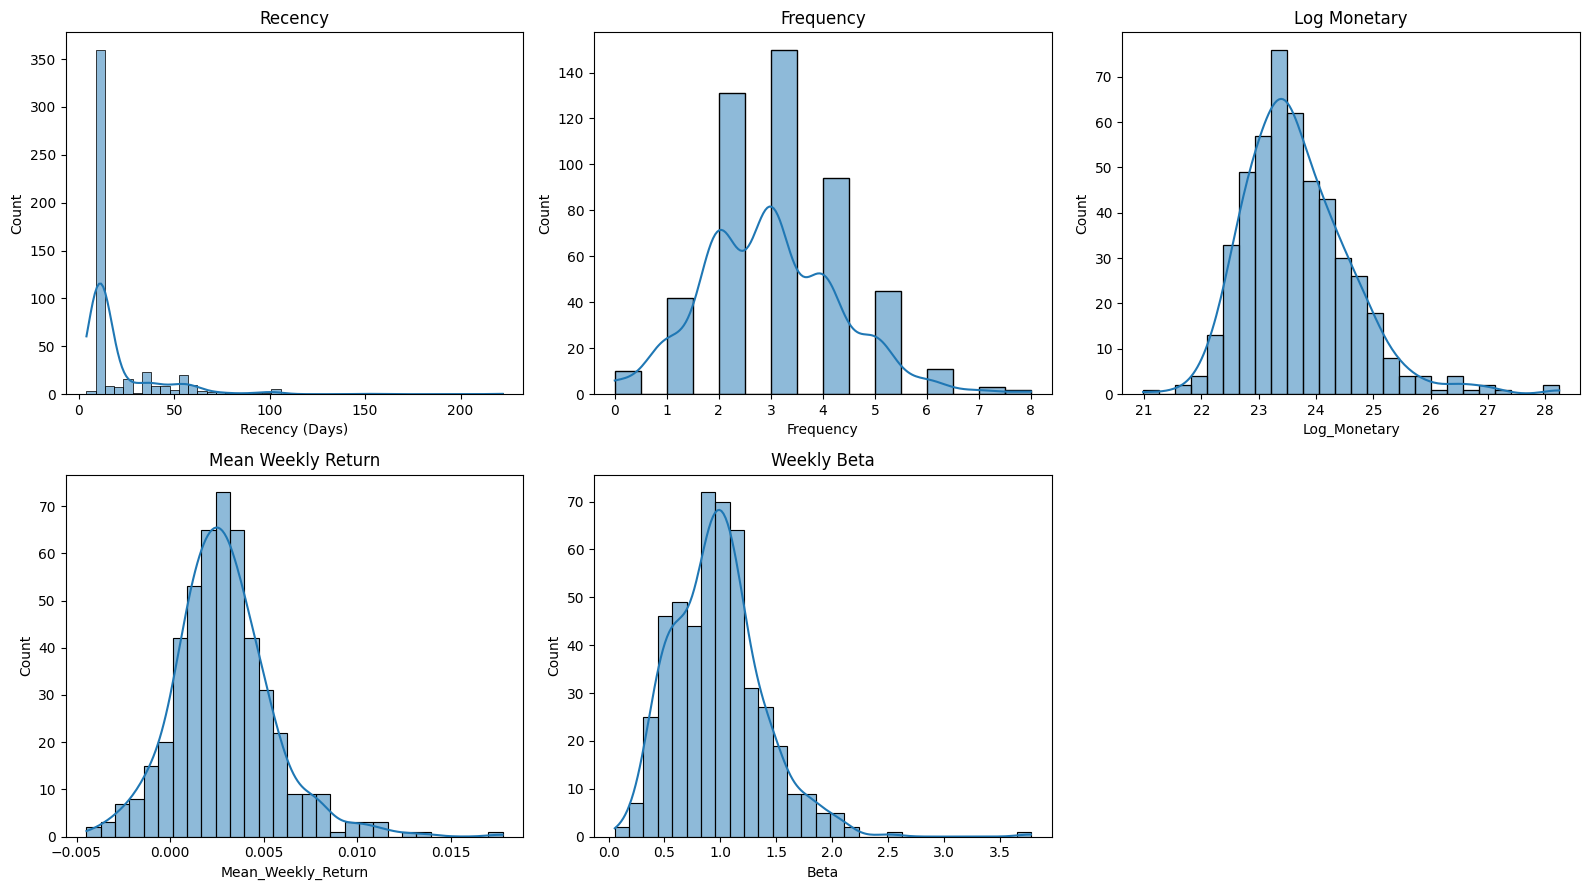

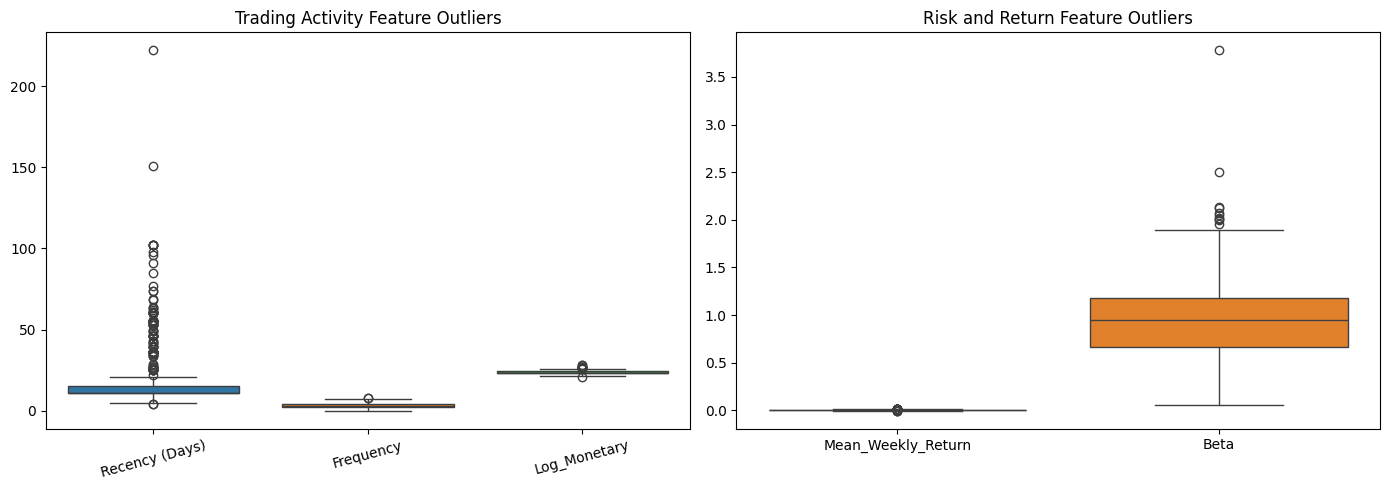

In [168]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create copies for inspection
activity_inspection = activity_features.copy()

# Apply log transformation to Monetary values
activity_inspection['Log_Monetary'] = np.log1p(activity_inspection['Monetary (USD)'])

# Calculate skewness
skewness = activity_inspection[['Recency (Days)', 'Frequency', 'Log_Monetary']].skew()

print("Trading Activity Feature Skewness:")
print(skewness.round(3))

print("\nRisk and Return Feature Skewness:")
print(risk_features.skew().round(3))

# Plot distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

features_to_plot = [
    (activity_inspection['Recency (Days)'], 'Recency'),
    (activity_inspection['Frequency'], 'Frequency'),
    (activity_inspection['Log_Monetary'], 'Log Monetary'),
    (risk_features['Mean_Weekly_Return'], 'Mean Weekly Return'),
    (risk_features['Beta'], 'Weekly Beta')
]

for ax, (series, title) in zip(axes.flat, features_to_plot):
    sns.histplot(series.dropna(), kde=True, ax=ax)
    ax.set_title(title)

# Hide unused sixth subplot
axes.flat[5].set_visible(False)

plt.tight_layout()
plt.show()

# Plot boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Trading activity feature boxplots
sns.boxplot(
    data=activity_inspection[
        ['Recency (Days)', 'Frequency', 'Log_Monetary']
    ],  ax=axes[0]
)

axes[0].set_title('Trading Activity Feature Outliers')
axes[0].tick_params(axis='x', rotation=15)

# Risk and return feature boxplots
sns.boxplot(data=risk_features, ax=axes[1])

axes[1].set_title('Risk and Return Feature Outliers')

plt.tight_layout()
plt.show()

In [169]:
def calculate_outliers(data):

    results = []

    for column in data.columns:
        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)

        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = (
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        )

        results.append({
            'Feature': column,
            'Lower_Bound': lower_bound,
            'Upper_Bound': upper_bound,
            'Outlier_Count': outliers.sum(),
            'Outlier_Percentage': outliers.mean() * 100
        })

    return pd.DataFrame(results)


# Check risk and return outliers
risk_outliers = calculate_outliers(risk_features)

# Check trading activity outliers after log transformation
activity_outliers = calculate_outliers(
    activity_inspection[['Recency (Days)', 'Frequency', 'Log_Monetary']])

print("Risk and Return Outliers:")
display(risk_outliers)

print("Trading Activity Outliers:")
display(activity_outliers)

Risk and Return Outliers:


,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Mean_Weekly_Return,-0.003354,0.008743,15,3.07377
1,Beta,-0.102348,1.948271,10,2.04918


Trading Activity Outliers:


,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Recency (Days),5.00000,21.000000,113,23.155738
1,Frequency,-1.00000,7.000000,2,0.409836
2,Log_Monetary,21.33375,25.907151,13,2.663934


In [170]:
def get_outliers(df, features):

    for feature in features:

        Q1 = df[feature].quantile(0.25)
        Q3 = df[feature].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df[
            (df[feature] < lower) |
            (df[feature] > upper)
        ]

        print(f"\n{'='*50}")
        print(f"Outliers for: {feature}")
        print(f"{'='*50}")

        display(outliers[[feature]])

# Identify Risk and Return outliers
print("RISK AND RETURN OUTLIERS")

risk_outlier_details = get_outliers(risk_features, ['Mean_Weekly_Return', 'Beta'])

# Identify Trading Activity outliers
print("TRADING ACTIVITY OUTLIERS")

activity_outlier_details = get_outliers(
    activity_inspection,
    ['Recency (Days)', 'Frequency', 'Log_Monetary']
)

RISK AND RETURN OUTLIERS

Outliers for: Mean_Weekly_Return


,Mean_Weekly_Return
ANET,0.010310
AVGO,0.010133
AXON,0.009767
BAX,-0.003803
CVNA,0.010964
DG,-0.003516
EL,-0.004468
FIX,0.011297
NVDA,0.013624
PLTR,0.009613



Outliers for: Beta


,Beta
BE,2.017079
CCL,1.958835
COHR,2.139305
CVNA,3.778560
NVDA,2.125954
PLTR,2.003194
TSLA,2.045761
TWLO,2.073379
VRT,2.001480
XYZ,2.504520


TRADING ACTIVITY OUTLIERS

Outliers for: Recency (Days)


,Recency (Days)
ADI,36
AES,54
AJG,4
AKAM,53
ALL,36
...,...
WEC,151
WYNN,47
XYL,36
XYZ,49



Outliers for: Frequency


,Frequency
CI,8
HSY,8



Outliers for: Log_Monetary


,Log_Monetary
AAPL,27.158299
AMD,26.469999
AMZN,26.872112
AVGO,26.534523
GOOG,26.035607
GOOGL,26.408138
LLY,25.938104
META,26.768059
MSFT,27.005342
NVDA,28.232786


In [171]:
from sklearn.preprocessing import StandardScaler

# Transform trading activity features
activity_transformed = activity_features.copy()
activity_transformed['Monetary (USD)'] = np.log1p(activity_transformed['Monetary (USD)'])

# Standardise risk and return
risk_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_features),
    index=risk_features.index,
    columns=risk_features.columns
)

# Standardise trading activity

activity_scaler = StandardScaler()

activity_scaled = pd.DataFrame(
    activity_scaler.fit_transform(activity_transformed),
    index=activity_transformed.index,
    columns=activity_transformed.columns
)

# Verify standardisation
print("Risk and Return Standardised Mean:")
print(risk_scaled.mean().round(3))

print("\nRisk and Return Standardised SD:")
print(risk_scaled.std(ddof=0).round(3))

print("\nTrading Activity Standardised Mean:")
print(activity_scaled.mean().round(3))

print("\nTrading Activity Standardised SD:")
print(activity_scaled.std(ddof=0).round(3))

Risk and Return Standardised Mean:
Mean_Weekly_Return    0.0
Beta                 -0.0
dtype: float64

Risk and Return Standardised SD:
Mean_Weekly_Return    1.0
Beta                  1.0
dtype: float64

Trading Activity Standardised Mean:
Recency (Days)   -0.0
Frequency        -0.0
Monetary (USD)   -0.0
dtype: float64

Trading Activity Standardised SD:
Recency (Days)    1.0
Frequency         1.0
Monetary (USD)    1.0
dtype: float64


##2.2 Agglomerative clustering

###Dendrograms

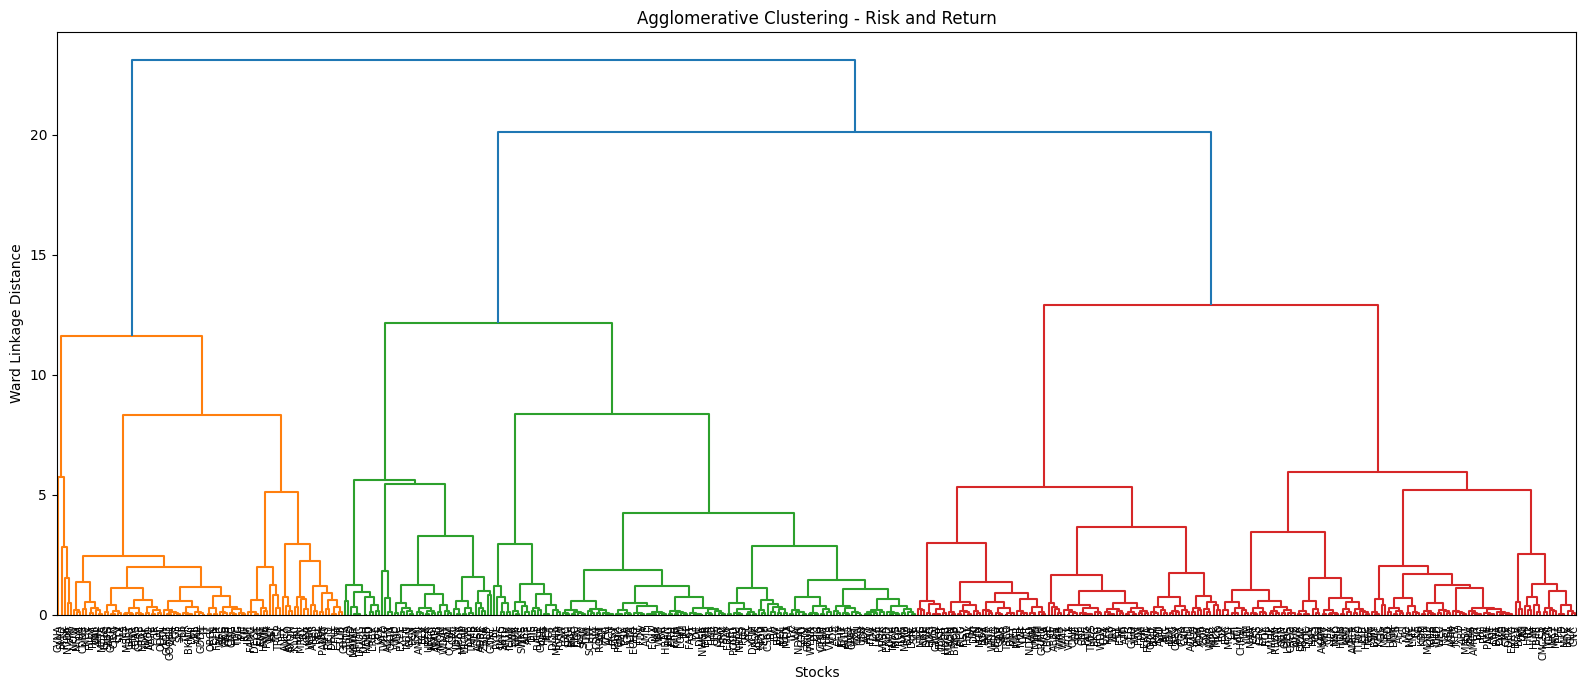

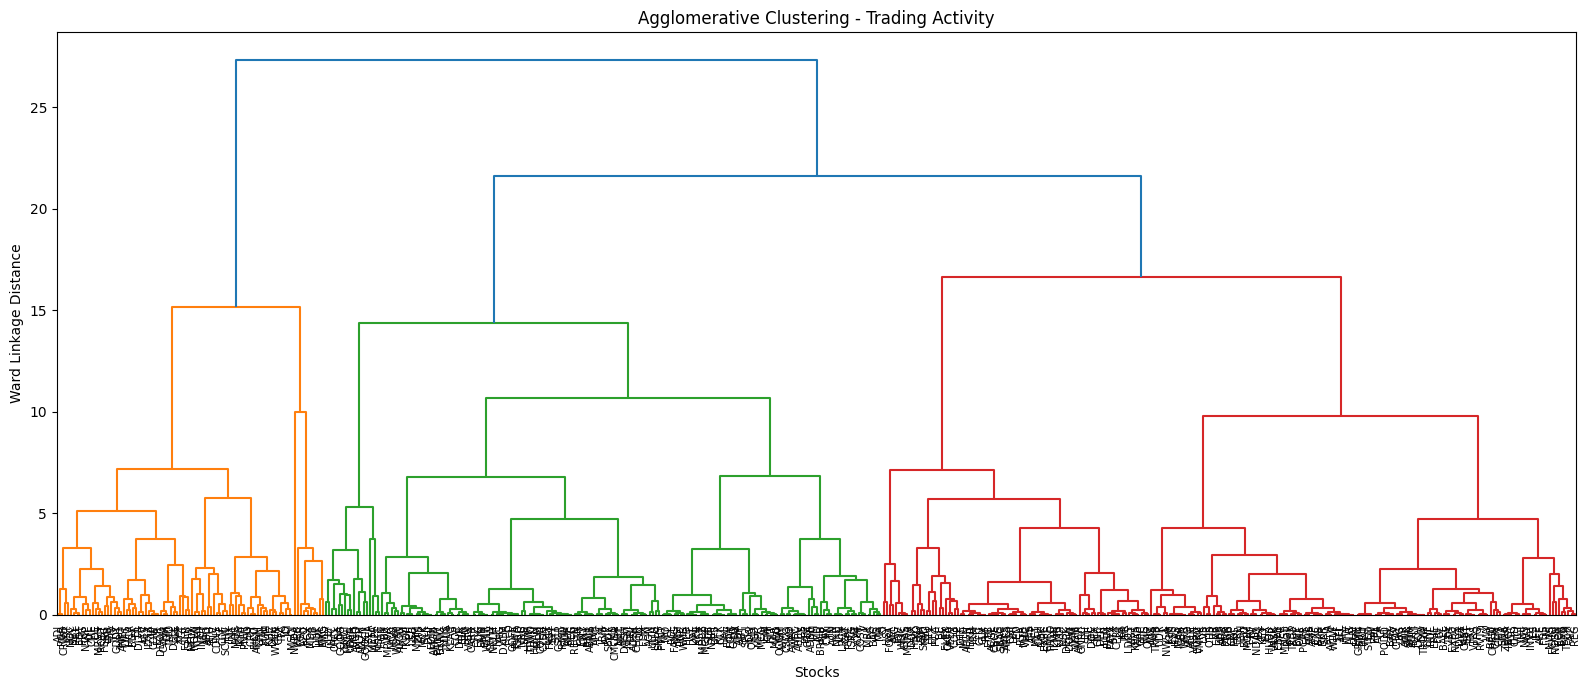

In [172]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Risk and Return Dendrogram
risk_linkage = linkage(risk_scaled, method='ward', metric='euclidean')
plt.figure(figsize=(16, 7))
dendrogram(
    risk_linkage,
    labels=risk_scaled.index.tolist(),
    leaf_rotation=90,
    leaf_font_size=7
)

plt.title('Agglomerative Clustering - Risk and Return')
plt.xlabel('Stocks')
plt.ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.savefig('risk_return_dendrogram.png', dpi=300)
plt.show()

# Trading Activity Dendrogram
activity_linkage = linkage(
    activity_scaled,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(16, 7))
dendrogram(
    activity_linkage,
    labels=activity_scaled.index.tolist(),
    leaf_rotation=90,
    leaf_font_size=7
)

plt.title('Agglomerative Clustering - Trading Activity')
plt.xlabel('Stocks')
plt.ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.savefig('trading_activity_dendrogram.png', dpi=300)
plt.show()

###Silhouette Score

In [173]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

def evaluate_agglomerative(X, linkage_matrix):

    results = []

    n = len(X)
    for k in range(2, min(8, n - 1) + 1):

        # Fit Agglomerative clustering
        model = AgglomerativeClustering(
            n_clusters=k, linkage='ward', metric='euclidean'
        )

        labels = model.fit_predict(X)

        # Calculate silhouette score
        silhouette = silhouette_score(X, labels)

        # Calculate cluster sizes
        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            'Clusters': k,
            'Silhouette_Score': silhouette,
            'Cluster_Sizes': cluster_sizes.to_dict(),
            'Smallest_Cluster': cluster_sizes.min(),
            'Largest_Cluster': cluster_sizes.max()
        })

    return pd.DataFrame(results)

# Evaluate risk and return
risk_agg_results = evaluate_agglomerative(
    risk_scaled, risk_linkage
)

# Evaluate trading activity
activity_agg_results = evaluate_agglomerative(
    activity_scaled, activity_linkage
)

print("Risk and Return Agglomerative Results:")
display(risk_agg_results)

print("\nTrading Activity Agglomerative Results:")
display(activity_agg_results)

Risk and Return Agglomerative Results:


,Clusters,Silhouette_Score,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,2,0.339888,"{0: 396, 1: 92}",92,396
1,3,0.292905,"{0: 212, 1: 92, 2: 184}",92,212
2,4,0.265427,"{0: 184, 1: 92, 2: 114, 3: 98}",92,184
3,5,0.287282,"{0: 92, 1: 136, 2: 114, 3: 98, 4: 48}",48,136
4,6,0.304064,"{0: 136, 1: 87, 2: 114, 3: 98, 4: 48, 5: 5}",5,136
5,7,0.306064,"{0: 87, 1: 48, 2: 114, 3: 98, 4: 114, 5: 5, 6:...",5,114
6,8,0.313846,"{0: 114, 1: 48, 2: 5, 3: 98, 4: 114, 5: 31, 6:...",5,114



Trading Activity Agglomerative Results:


,Clusters,Silhouette_Score,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,2,0.369340,"{0: 402, 1: 86}",86,402
1,3,0.261434,"{0: 223, 1: 86, 2: 179}",86,223
2,4,0.251355,"{0: 86, 1: 137, 2: 179, 3: 86}",86,179
3,5,0.270088,"{0: 179, 1: 137, 2: 10, 3: 86, 4: 76}",10,179
4,6,0.291391,"{0: 161, 1: 137, 2: 10, 3: 86, 4: 76, 5: 18}",10,161
5,7,0.280443,"{0: 10, 1: 137, 2: 71, 3: 86, 4: 76, 5: 18, 6:...",10,137
6,8,0.281642,"{0: 137, 1: 76, 2: 71, 3: 86, 4: 9, 5: 18, 6: ...",1,137


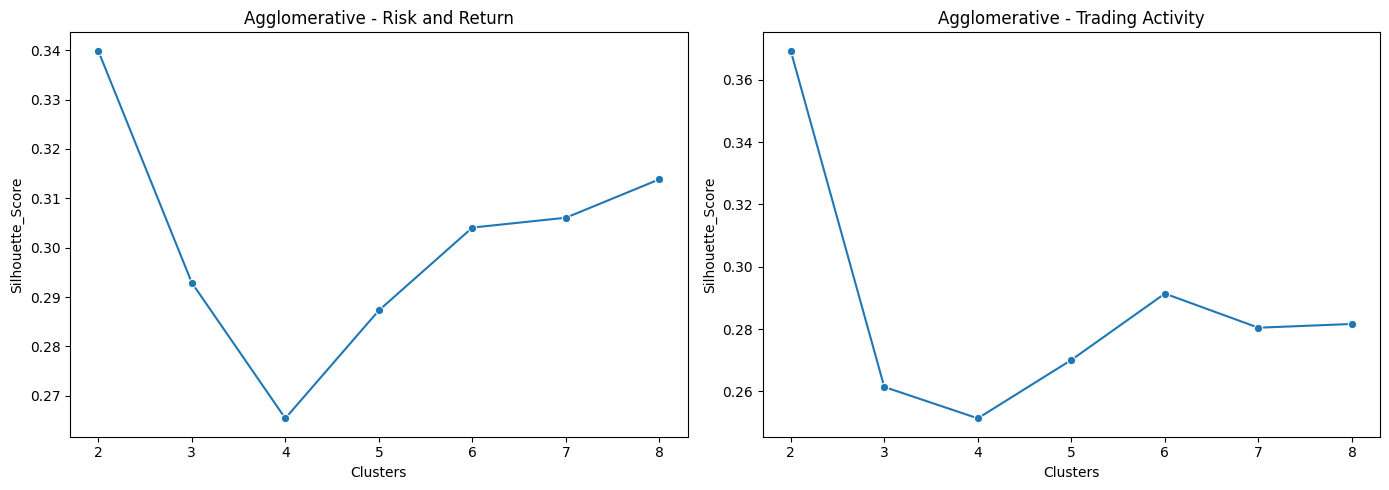

In [174]:
# Create silhouette comparison plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Risk and return
sns.lineplot(
    data=risk_agg_results,
    x='Clusters',
    y='Silhouette_Score',
    marker='o', ax=axes[0]
)

axes[0].set_title('Agglomerative - Risk and Return')
axes[0].set_xticks(range(2, 9))

# Trading activity
sns.lineplot(
    data=activity_agg_results,
    x='Clusters',
    y='Silhouette_Score',
    marker='o', ax=axes[1]
)

axes[1].set_title('Agglomerative - Trading Activity')
axes[1].set_xticks(range(2, 9))

plt.tight_layout()
plt.savefig('agglomerative_silhouette_comparison.png', dpi=300)
plt.show()

In [175]:
# Select the final cluster counts
SELECTED_K_RISK = 3
SELECTED_K_ACTIVITY = 3

# Risk and Return Agglomerative Model
risk_agg_model = AgglomerativeClustering(
    n_clusters=SELECTED_K_RISK,
    linkage='ward', metric='euclidean'
)

risk_agg_labels = risk_agg_model.fit_predict(risk_scaled)

# Trading Activity Agglomerative Model
activity_agg_model = AgglomerativeClustering(n_clusters=SELECTED_K_ACTIVITY,
    linkage='ward', metric='euclidean'
)
activity_agg_labels = activity_agg_model.fit_predict(activity_scaled)


# Store labels
risk_agg_clusters = pd.Series(
    risk_agg_labels + 1,
    index=risk_features.index,
    name='Risk_Agglomerative_Cluster'
)

activity_agg_clusters = pd.Series(
    activity_agg_labels + 1,
    index=activity_features.index,
    name='Activity_Agglomerative_Cluster'
)

print("Risk and Return Cluster Counts:")
print(risk_agg_clusters.value_counts().sort_index())

print("\nTrading Activity Cluster Counts:")
print(activity_agg_clusters.value_counts().sort_index())

Risk and Return Cluster Counts:
Risk_Agglomerative_Cluster
1    212
2     92
3    184
Name: count, dtype: int64

Trading Activity Cluster Counts:
Activity_Agglomerative_Cluster
1    223
2     86
3    179
Name: count, dtype: int64


In [204]:
act_alt = activity_features.copy()
act_alt['Recency (Days)'] = np.log1p(act_alt['Recency (Days)'])
act_alt['Monetary (USD)'] = np.log1p(act_alt['Monetary (USD)'])
print('Skew of log1p(Recency):', round(act_alt['Recency (Days)'].skew(), 3))
alt_scaled = StandardScaler().fit_transform(act_alt)
alt_labels = AgglomerativeClustering(n_clusters=SELECTED_K_ACTIVITY, linkage='ward').fit_predict(alt_scaled)
print('ARI raw Recency vs log1p Recency (Ward):',
      round(adjusted_rand_score(activity_agg_labels, alt_labels), 3))

Skew of log1p(Recency): 1.584
ARI raw Recency vs log1p Recency (Ward): 0.737


##2.3 K means clustering

In [176]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def evaluate_kmeans(X):

    results = []

    n = len(X)
    for k in range(2, min(8, n - 1) + 1):

        # Initialise K-means
        model = KMeans(n_clusters=k, random_state=42, n_init=50)

        # Fit model
        labels = model.fit_predict(X)

        # Calculate silhouette score
        silhouette = silhouette_score(X, labels)

        # Calculate inertia
        inertia = model.inertia_

        # Calculate cluster sizes
        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            'Clusters': k,
            'Silhouette_Score': silhouette,
            'Inertia': inertia,
            'Cluster_Sizes': cluster_sizes.to_dict(),
            'Smallest_Cluster': cluster_sizes.min(),
            'Largest_Cluster': cluster_sizes.max()
        })

    return pd.DataFrame(results)


# Evaluate risk and return
risk_kmeans_results = evaluate_kmeans(risk_scaled)

# Evaluate trading activity
activity_kmeans_results = evaluate_kmeans(activity_scaled)


print("Risk and Return K-means Results:")
display(risk_kmeans_results)

print("\nTrading Activity K-means Results:")
display(activity_kmeans_results)

Risk and Return K-means Results:


,Clusters,Silhouette_Score,Inertia,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,2,0.386804,625.010413,"{0: 345, 1: 143}",143,345
1,3,0.327815,464.070814,"{0: 203, 1: 166, 2: 119}",119,203
2,4,0.325222,373.928346,"{0: 167, 1: 150, 2: 130, 3: 41}",41,167
3,5,0.338879,311.854195,"{0: 164, 1: 127, 2: 114, 3: 28, 4: 55}",28,164
4,6,0.328178,266.927170,"{0: 56, 1: 20, 2: 137, 3: 77, 4: 115, 5: 83}",20,137
5,7,0.334495,228.199443,"{0: 86, 1: 143, 2: 5, 3: 48, 4: 73, 5: 92, 6: 41}",5,143
6,8,0.357568,196.031453,"{0: 139, 1: 30, 2: 76, 3: 48, 4: 82, 5: 5, 6: ...",5,139



Trading Activity K-means Results:


,Clusters,Silhouette_Score,Inertia,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,2,0.423769,1071.585297,"{0: 420, 1: 68}",68,420
1,3,0.325091,800.746441,"{0: 151, 1: 274, 2: 63}",63,274
2,4,0.341383,612.475070,"{0: 214, 1: 122, 2: 61, 3: 91}",61,214
3,5,0.357967,517.074772,"{0: 122, 1: 87, 2: 68, 3: 200, 4: 11}",11,200
4,6,0.345333,439.829795,"{0: 143, 1: 106, 2: 68, 3: 40, 4: 120, 5: 11}",11,143
5,7,0.348066,390.204268,"{0: 105, 1: 64, 2: 15, 3: 144, 4: 40, 5: 119, ...",1,144
6,8,0.342583,343.594208,"{0: 18, 1: 151, 2: 65, 3: 105, 4: 1, 5: 89, 6:...",1,151


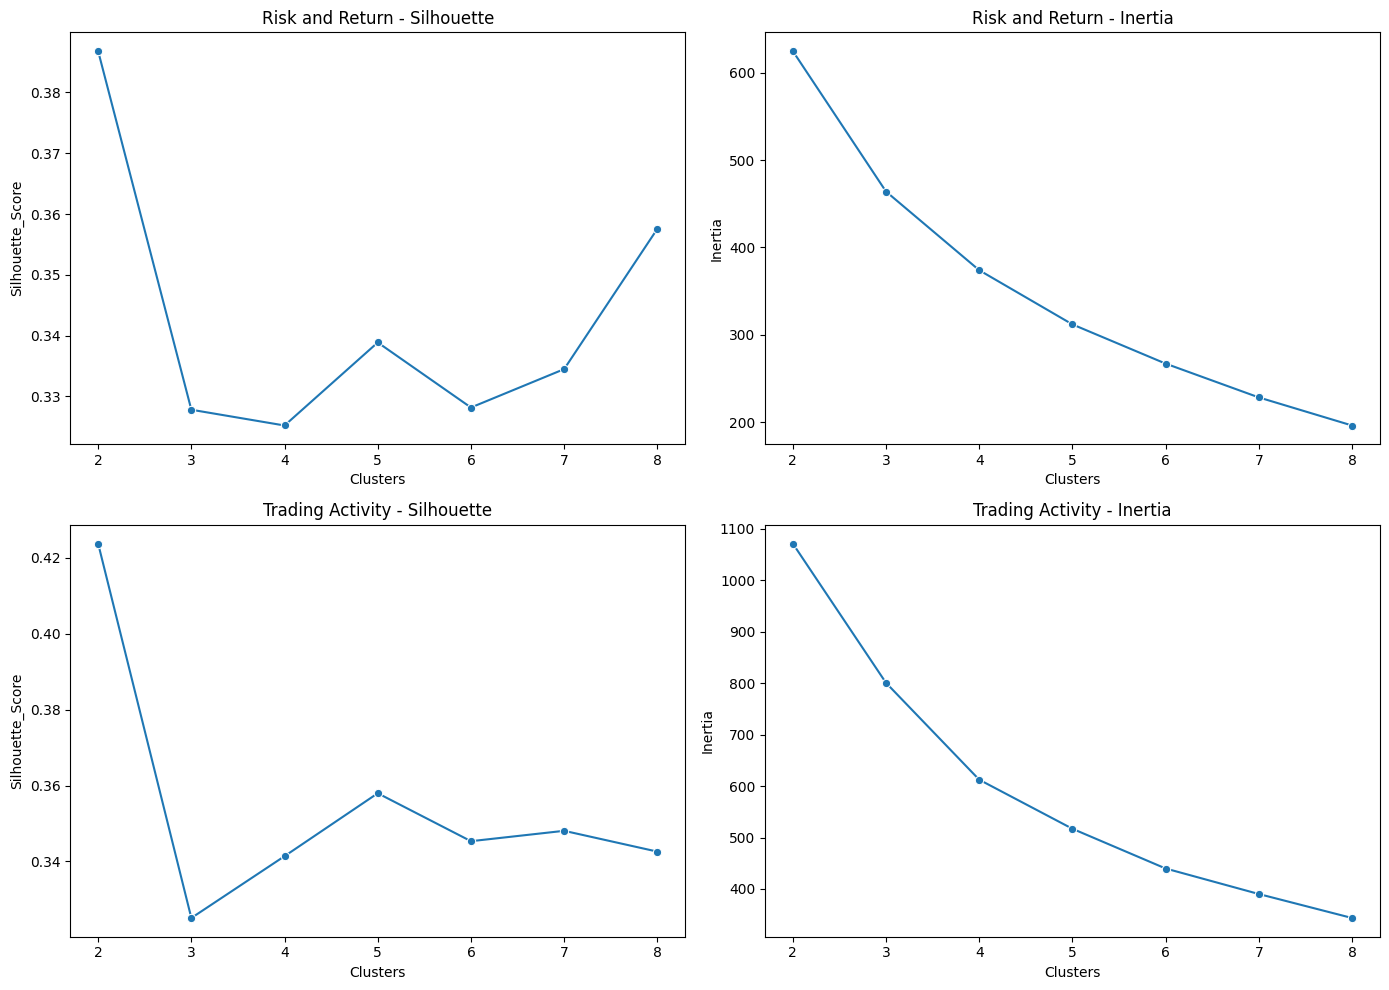

In [177]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Risk and return silhouette
sns.lineplot(
    data=risk_kmeans_results,
    x='Clusters',
    y='Silhouette_Score',
    marker='o', ax=axes[0, 0]
)

axes[0, 0].set_title('Risk and Return - Silhouette')
axes[0, 0].set_xticks(range(2, 9))

# Risk and return inertia
sns.lineplot(
    data=risk_kmeans_results,
    x='Clusters',
    y='Inertia',
    marker='o', ax=axes[0, 1]
)

axes[0, 1].set_title('Risk and Return - Inertia')
axes[0, 1].set_xticks(range(2, 9))

# Trading activity silhouette
sns.lineplot(
    data=activity_kmeans_results,
    x='Clusters',
    y='Silhouette_Score',
    marker='o', ax=axes[1, 0]
)

axes[1, 0].set_title('Trading Activity - Silhouette')
axes[1, 0].set_xticks(range(2, 9))

# Trading activity inertia
sns.lineplot(
    data=activity_kmeans_results,
    x='Clusters',
    y='Inertia',
    marker='o', ax=axes[1, 1]
)

axes[1, 1].set_title('Trading Activity - Inertia')
axes[1, 1].set_xticks(range(2, 9))

plt.tight_layout()
plt.savefig('kmeans_evaluation.png', dpi=300)
plt.show()

In [203]:
# Select the final K-means cluster counts
SELECTED_K_RISK_KMEANS = 3
SELECTED_K_ACTIVITY_KMEANS = 4

# Risk and Return K-means
risk_kmeans_model = KMeans(n_clusters=SELECTED_K_RISK_KMEANS, random_state=42, n_init=50)
risk_kmeans_labels = risk_kmeans_model.fit_predict(risk_scaled)

# Trading Activity K-means
activity_kmeans_model = KMeans(n_clusters=SELECTED_K_ACTIVITY_KMEANS, random_state=42, n_init=50)
activity_kmeans_labels = activity_kmeans_model.fit_predict(activity_scaled)

# Store cluster labels
risk_kmeans_clusters = pd.Series(
    risk_kmeans_labels + 1,
    index=risk_features.index,
    name='Risk_KMeans_Cluster'
)

activity_kmeans_clusters = pd.Series(
    activity_kmeans_labels + 1,
    index=activity_features.index,
    name='Activity_KMeans_Cluster'
)

print("Risk and Return K-means Cluster Counts:")
print(risk_kmeans_clusters.value_counts().sort_index())

print("\nTrading Activity K-means Cluster Counts:")
print(activity_kmeans_clusters.value_counts().sort_index())

Risk and Return K-means Cluster Counts:
Risk_KMeans_Cluster
1    203
2    166
3    119
Name: count, dtype: int64

Trading Activity K-means Cluster Counts:
Activity_KMeans_Cluster
1    214
2    122
3     61
4     91
Name: count, dtype: int64


In [207]:
for name, X, k in [('Risk', risk_scaled, SELECTED_K_RISK_KMEANS),
                   ('Activity', activity_scaled, SELECTED_K_ACTIVITY_KMEANS)]:
    base = KMeans(n_clusters=k, random_state=42, n_init=50).fit_predict(X)
    aris = [adjusted_rand_score(base, KMeans(n_clusters=k, random_state=s, n_init=50).fit_predict(X))
            for s in range(1, 11)]
    print(f'{name} (k={k}): K-means ARI vs seed 42 across 10 seeds, min =', round(min(aris), 3))

Risk (k=3): K-means ARI vs seed 42 across 10 seeds, min = 1.0
Activity (k=4): K-means ARI vs seed 42 across 10 seeds, min = 1.0


##2.4 Cluster profiles and algorithm comparison

In [208]:
# Risk and Return Cluster Profiles

risk_profile_data = risk_features.copy()
risk_profile_data['Agglomerative_Cluster'] = (risk_agg_clusters)
risk_profile_data['KMeans_Cluster'] = (risk_kmeans_clusters)

# Agglomerative profiles
risk_agg_profile = (
    risk_profile_data
    .groupby('Agglomerative_Cluster')
    .agg({
        'Mean_Weekly_Return': 'mean',
        'Beta': 'mean',
        'Agglomerative_Cluster': 'count'
    })
    .rename(columns={'Agglomerative_Cluster': 'Number_of_Stocks'})
)

# K-means profiles
risk_kmeans_profile = (
    risk_profile_data
    .groupby('KMeans_Cluster')
    .agg({
        'Mean_Weekly_Return': 'mean',
        'Beta': 'mean',
        'KMeans_Cluster': 'count'
    })
    .rename(columns={'KMeans_Cluster': 'Number_of_Stocks'})
)

# Trading Activity Cluster Profiles

activity_profile_data = activity_features.copy()

activity_profile_data['Agglomerative_Cluster'] = (activity_agg_clusters)

activity_profile_data['KMeans_Cluster'] = (activity_kmeans_clusters)

# Agglomerative profiles
activity_agg_profile = (
    activity_profile_data
    .groupby('Agglomerative_Cluster')
    .agg({
        'Recency (Days)': 'mean',
        'Frequency': 'mean',
        'Monetary (USD)': 'mean',
        'Agglomerative_Cluster': 'count'
    })
    .rename(columns={
        'Agglomerative_Cluster': 'Number_of_Stocks'
    })
)

# K-means profiles
activity_kmeans_profile = (
    activity_profile_data
    .groupby('KMeans_Cluster')
    .agg({
        'Recency (Days)': 'mean',
        'Frequency': 'mean',
        'Monetary (USD)': 'mean',
        'KMeans_Cluster': 'count'
    })
    .rename(columns={
        'KMeans_Cluster': 'Number_of_Stocks'
    })
)

# Display profiles
print("Risk and Return - Agglomerative Profiles")
display(risk_agg_profile.round(4))

print("Risk and Return - K-means Profiles")
display(risk_kmeans_profile.round(4))

print("Trading Activity - Agglomerative Profiles")
display(activity_agg_profile.round(2))

print("Trading Activity - K-means Profiles")
display(activity_kmeans_profile.round(2))

Risk and Return - Agglomerative Profiles


,Mean_Weekly_Return,Beta,Number_of_Stocks
Agglomerative_Cluster,,,
1,0.0025,0.6371,212
2,0.0063,1.2981,92
3,0.0015,1.1998,184


Risk and Return - K-means Profiles


,Mean_Weekly_Return,Beta,Number_of_Stocks
KMeans_Cluster,,,
1,0.0026,0.6323,203
2,0.0010,1.1389,166
3,0.0060,1.3264,119


Trading Activity - Agglomerative Profiles


,Recency (Days),Frequency,Monetary (USD),Number_of_Stocks
Agglomerative_Cluster,,,,
1,12.89,3.42,1.101312e+10,223
2,57.00,1.98,4.824805e+10,86
3,12.15,2.94,7.024891e+10,179


Trading Activity - K-means Profiles


,Recency (Days),Frequency,Monetary (USD),Number_of_Stocks
KMeans_Cluster,,,,
1,13.29,2.37,1.517075e+10,214
2,13.94,4.55,1.501539e+10,122
3,66.02,1.67,5.618009e+10,61
4,15.14,3.23,1.173012e+11,91


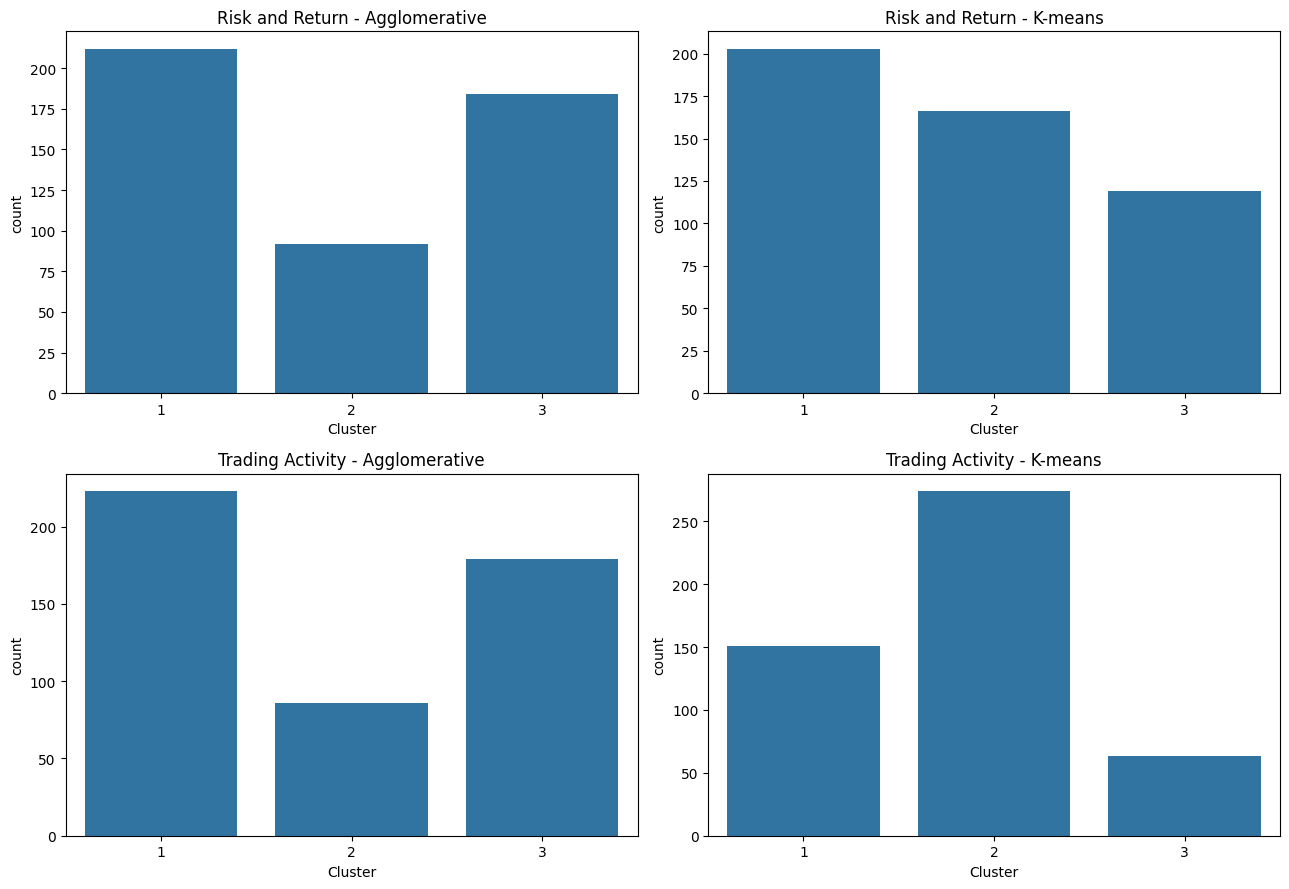

In [180]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Risk Agglomerative
sns.countplot(x=risk_agg_clusters, ax=axes[0, 0])

axes[0, 0].set_title('Risk and Return - Agglomerative')
axes[0, 0].set_xlabel('Cluster')

# Risk K-means
sns.countplot(x=risk_kmeans_clusters, ax=axes[0, 1])

axes[0, 1].set_title('Risk and Return - K-means')
axes[0, 1].set_xlabel('Cluster')

# Activity Agglomerative
sns.countplot(x=activity_agg_clusters, ax=axes[1, 0])

axes[1, 0].set_title('Trading Activity - Agglomerative')
axes[1, 0].set_xlabel('Cluster')

# Activity K-means
sns.countplot(x=activity_kmeans_clusters, ax=axes[1, 1])

axes[1, 1].set_title('Trading Activity - K-means')
axes[1, 1].set_xlabel('Cluster')

plt.tight_layout()
plt.savefig('cluster_size_comparison.png', dpi=300)
plt.show()

PCA Explained Variance:
[0.4579 0.3365]
Total Variance Explained: 79.44 %


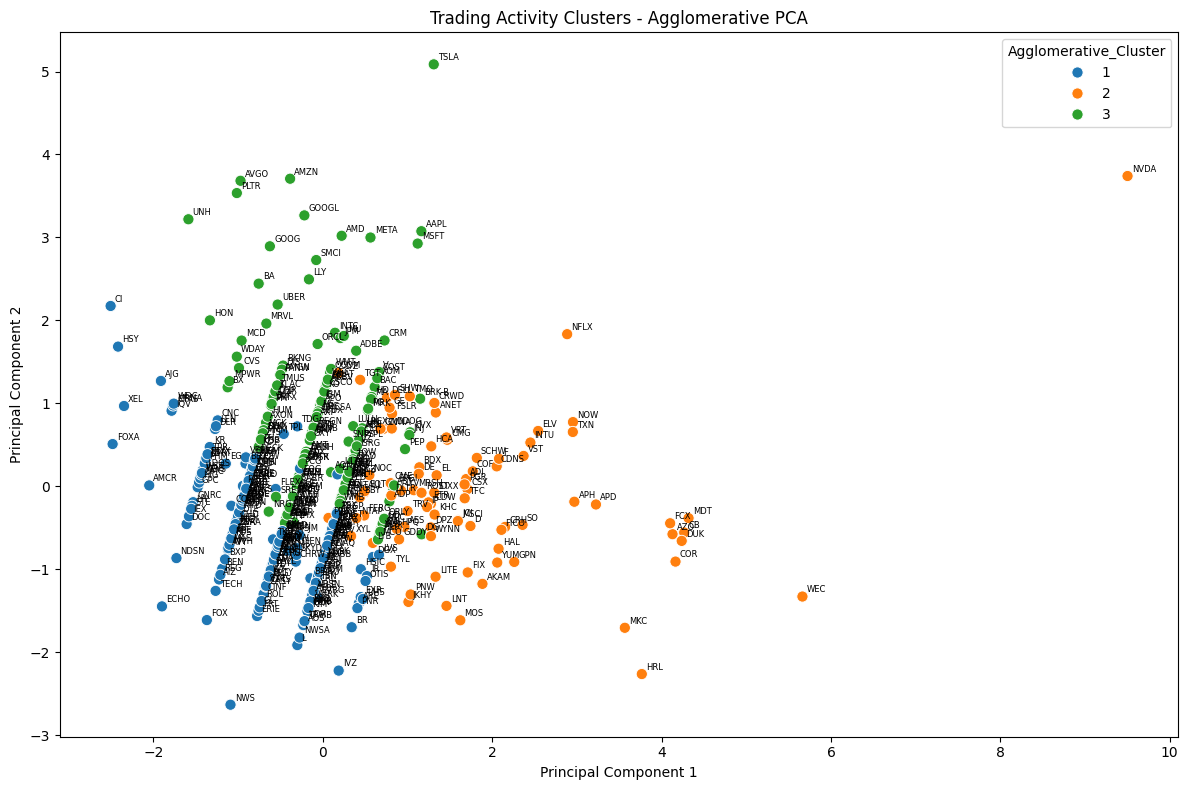

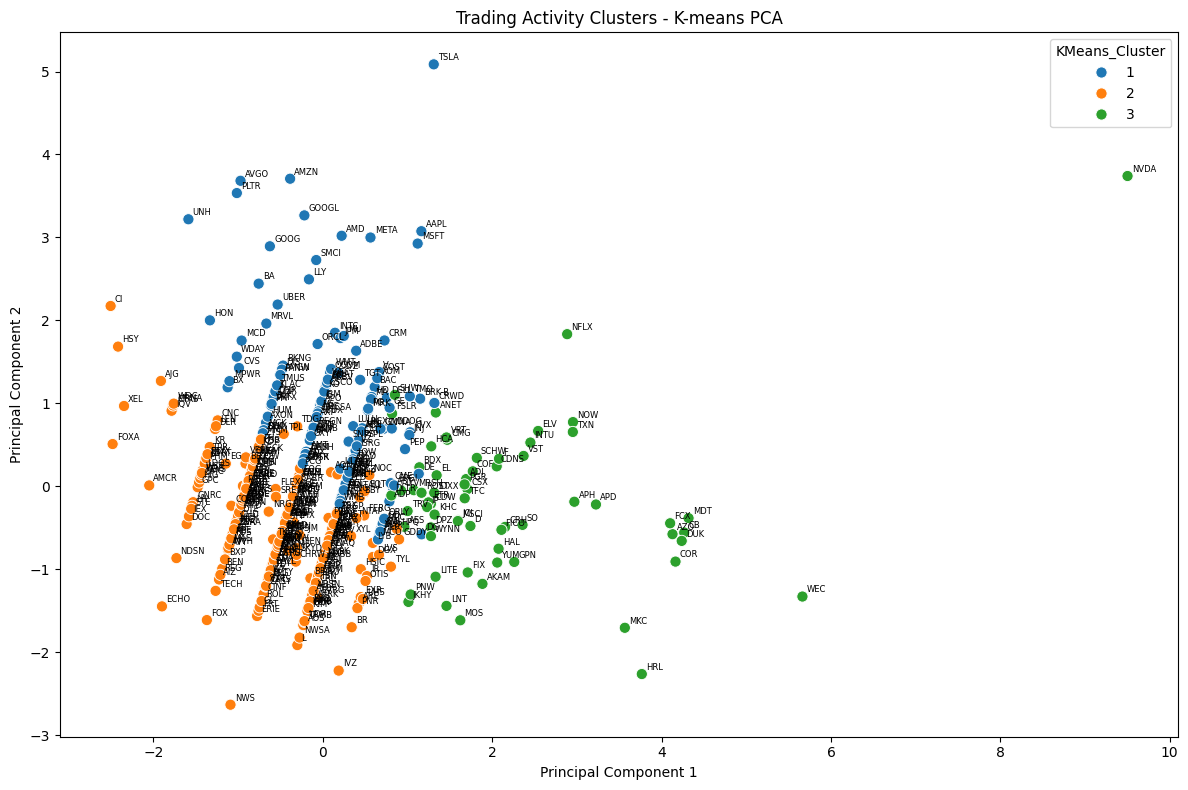

In [181]:
from sklearn.decomposition import PCA

# PCA for Trading Activity
pca = PCA(n_components=2)

activity_pca = pca.fit_transform(activity_scaled)
activity_pca_df = pd.DataFrame(activity_pca, columns=['PC1', 'PC2'], index=activity_scaled.index)
activity_pca_df['Agglomerative_Cluster'] = (activity_agg_clusters)
activity_pca_df['KMeans_Cluster'] = (activity_kmeans_clusters)

print("PCA Explained Variance:")
print(pca.explained_variance_ratio_.round(4))

print(
    "Total Variance Explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2), "%"
)

# Plot PCA - Agglomerative
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=activity_pca_df,
    x='PC1',
    y='PC2',
    hue='Agglomerative_Cluster', palette='tab10', s=65
)

for ticker, row in activity_pca_df.iterrows():

    plt.annotate(
        ticker,
        (row['PC1'], row['PC2']),
        fontsize=6,
        xytext=(3, 3),
        textcoords='offset points'
    )

plt.title('Trading Activity Clusters - Agglomerative PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.savefig('activity_agg_pca.png', dpi=300)
plt.show()

# Plot PCA - K-means

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=activity_pca_df,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='tab10',
    s=65
)

for ticker, row in activity_pca_df.iterrows():

    plt.annotate(
        ticker,
        (row['PC1'], row['PC2']),
        fontsize=6,
        xytext=(3, 3),
        textcoords='offset points'
    )

plt.title('Trading Activity Clusters - K-means PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.savefig('activity_kmeans_pca.png', dpi=300)
plt.show()

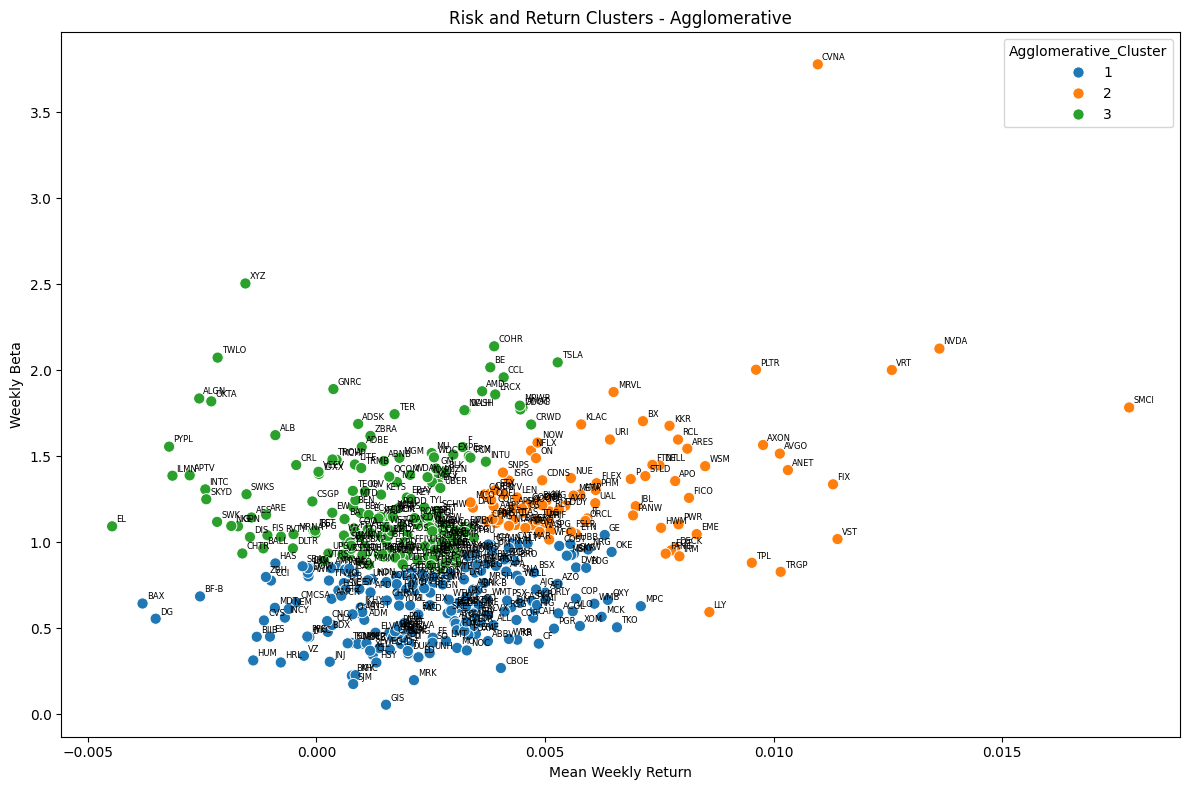

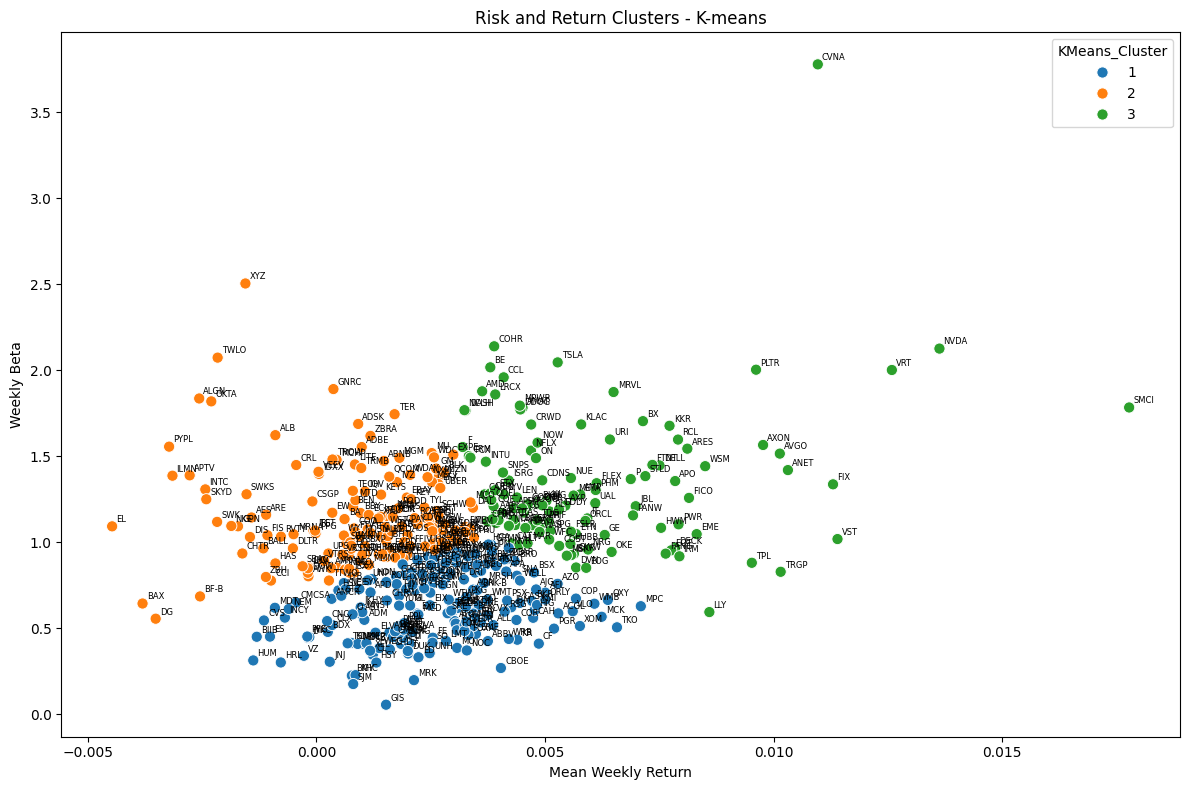

In [182]:
# Create plotting DataFrame
risk_plot_df = risk_features.copy()
risk_plot_df['Agglomerative_Cluster'] = risk_agg_clusters
risk_plot_df['KMeans_Cluster'] = risk_kmeans_clusters

# Agglomerative visualisation

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=risk_plot_df,
    x='Mean_Weekly_Return',
    y='Beta',
    hue='Agglomerative_Cluster', palette='tab10', s=65
)

for ticker, row in risk_plot_df.iterrows():

    plt.annotate(
        ticker,
        (row['Mean_Weekly_Return'], row['Beta']),
        fontsize=6,
        xytext=(3, 3),
        textcoords='offset points'
    )

plt.title('Risk and Return Clusters - Agglomerative')
plt.xlabel('Mean Weekly Return')
plt.ylabel('Weekly Beta')

plt.tight_layout()
plt.savefig('risk_agg_clusters.png', dpi=300)
plt.show()

# K-means visualisation

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=risk_plot_df,
    x='Mean_Weekly_Return',
    y='Beta',
    hue='KMeans_Cluster', palette='tab10', s=65
)

for ticker, row in risk_plot_df.iterrows():

    plt.annotate(
        ticker,
        (row['Mean_Weekly_Return'], row['Beta']),
        fontsize=6,
        xytext=(3, 3),
        textcoords='offset points'
    )

plt.title('Risk and Return Clusters - K-means')
plt.xlabel('Mean Weekly Return')
plt.ylabel('Weekly Beta')

plt.tight_layout()
plt.savefig('risk_kmeans_clusters.png', dpi=300)
plt.show()

In [209]:
from sklearn.metrics import adjusted_rand_score

# Compare risk and return algorithms

risk_ari = adjusted_rand_score(risk_agg_labels, risk_kmeans_labels)

# Compare trading activity algorithms

activity_ari = adjusted_rand_score(activity_agg_labels, activity_kmeans_labels)

# Display comparison
algorithm_comparison = pd.DataFrame({
    'Feature_Matrix': ['Risk and Return', 'Trading Activity'],
    'Agglomerative_Clusters': [SELECTED_K_RISK, SELECTED_K_ACTIVITY],
    'KMeans_Clusters': [SELECTED_K_RISK_KMEANS, SELECTED_K_ACTIVITY_KMEANS],
    'Adjusted_Rand_Index': [risk_ari, activity_ari]
})

algorithm_comparison

,Feature_Matrix,Agglomerative_Clusters,KMeans_Clusters,Adjusted_Rand_Index
0,Risk and Return,3,3,0.602229
1,Trading Activity,3,4,0.286550


In [184]:
# Combine all four clustering results
final_clusters = pd.DataFrame(index=common_shares)

final_clusters['Risk_Agglomerative'] = risk_agg_clusters
final_clusters['Risk_KMeans'] = risk_kmeans_clusters
final_clusters['Activity_Agglomerative'] = activity_agg_clusters
final_clusters['Activity_KMeans'] = activity_kmeans_clusters

# Display results
final_clusters.head(5)

,Risk_Agglomerative,Risk_KMeans,Activity_Agglomerative,Activity_KMeans
A,3,2,1,2
AAPL,2,3,3,1
ABBV,1,1,3,1
ABNB,3,2,3,1
ABT,1,1,3,1


In [197]:
# save the feature tables + four clusters
risk_features.to_csv('risk_return_features.csv')
activity_features.to_csv('rfm_features.csv')
final_clusters.to_csv('cluster_assignments_four_baselines.csv')

##2.5 RFM sensitivity and correlated inputs

###2.5.1 Correlation analysis

In [185]:
# Prepare transformed RFM features
rfm_correlation = activity_features.copy()

# Apply log1p to Monetary
rfm_correlation['Log_Monetary'] = np.log1p(rfm_correlation['Monetary (USD)'])

# Select required features
rfm_correlation = rfm_correlation[['Recency (Days)', 'Frequency', 'Log_Monetary']]

# Calculate Pearson correlation
correlation_matrix = rfm_correlation.corr(method='pearson')

print("RFM Correlation Matrix:")

display(correlation_matrix.round(3))

RFM Correlation Matrix:


,Recency (Days),Frequency,Log_Monetary
Recency (Days),1.000,-0.346,0.153
Frequency,-0.346,1.000,0.013
Log_Monetary,0.153,0.013,1.000


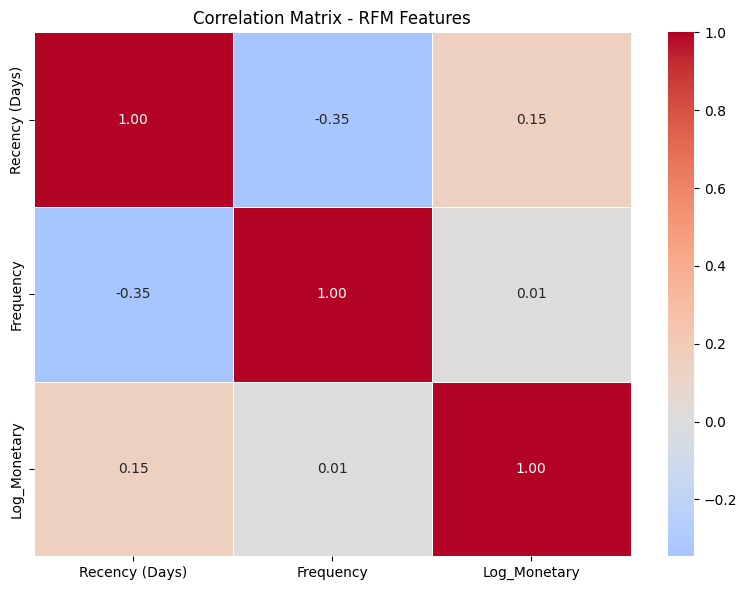

In [186]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix - RFM Features')
plt.tight_layout()
plt.savefig('rfm_correlation_heatmap.png', dpi=300)
plt.show()

In [187]:
# Extract unique correlation pairs
correlation_pairs = (
    correlation_matrix
    .where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = ['Feature_1', 'Feature_2', 'Correlation']

# Sort by absolute correlation
correlation_pairs['Absolute_Correlation'] = (correlation_pairs['Correlation'].abs())

correlation_pairs = correlation_pairs.sort_values('Absolute_Correlation', ascending=False)

display(correlation_pairs)

,Feature_1,Feature_2,Correlation,Absolute_Correlation
0,Recency (Days),Frequency,-0.346128,0.346128
1,Recency (Days),Log_Monetary,0.152835,0.152835
2,Frequency,Log_Monetary,0.012848,0.012848


###2.5.2 Removal of Monetary

In [188]:
# Select Recency and Frequency only
rf_features = activity_features[['Recency (Days)', 'Frequency']].copy()

# Ensure the same shares are retained
assert rf_features.index.equals(activity_features.index)

# Standardise reduced matrix afresh
rf_scaler = StandardScaler()

rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_features),
    index=rf_features.index,
    columns=rf_features.columns
)

print("Reduced R and F Feature Matrix:")
display(rf_scaled.head())
print("\nStandardised Means:", rf_scaled.mean().round(3))
print("\nStandardised Standard Deviations:", rf_scaled.std(ddof=0).round(3))

Reduced R and F Feature Matrix:


,Recency (Days),Frequency
A,-0.441208,-0.744058
AAPL,-0.441208,-0.744058
ABBV,-0.441208,0.009262
ABNB,-0.441208,0.009262
ABT,-0.441208,-1.497377



Standardised Means: Recency (Days)   -0.0
Frequency        -0.0
dtype: float64

Standardised Standard Deviations: Recency (Days)    1.0
Frequency         1.0
dtype: float64


In [189]:
# Fit Ward clustering using R and F
rf_ward_model = AgglomerativeClustering(
    n_clusters=SELECTED_K_ACTIVITY, linkage='ward', metric='euclidean'
)

rf_ward_labels = rf_ward_model.fit_predict(rf_scaled)

# Store reduced RFM clusters
rf_ward_clusters = pd.Series(
    rf_ward_labels + 1,
    index=rf_features.index,
    name='RF_Cluster'
)

print("R and F Cluster Sizes:", rf_ward_clusters.value_counts().sort_index())

R and F Cluster Sizes: RF_Cluster
1     90
2    273
3    125
Name: count, dtype: int64


In [190]:
# Calculate Adjusted Rand Index
rfm_sensitivity_ari = adjusted_rand_score(activity_agg_labels, rf_ward_labels)
print("Adjusted Rand Index (RFM vs RF):", round(rfm_sensitivity_ari, 4))

# Compare cluster assignments
sensitivity_comparison = pd.DataFrame({
    'Share': activity_features.index,
    'Original_RFM_Cluster': activity_agg_labels + 1,
    'Reduced_RF_Cluster': rf_ward_labels + 1,
    'Monetary (USD)': activity_features['Monetary (USD)'].values
})

sensitivity_comparison.head(5)

Adjusted Rand Index (RFM vs RF): 0.2682


,Share,Original_RFM_Cluster,Reduced_RF_Cluster,Monetary (USD)
0,A,1,3,1.400180e+10
1,AAPL,3,3,6.233034e+11
2,ABBV,3,2,6.837054e+10
3,ABNB,3,2,3.652850e+10
4,ABT,3,3,3.523027e+10


In [191]:
# Original RFM cluster profiles
original_rfm_profile = activity_features.copy()
original_rfm_profile['Cluster'] = activity_agg_labels + 1
original_rfm_profile = (
    original_rfm_profile
    .groupby('Cluster')
    .agg({
        'Recency (Days)': 'mean',
        'Frequency': 'mean',
        'Monetary (USD)': ['mean', 'median', 'count']
    })
)

# Reduced RF cluster profiles
reduced_rf_profile = activity_features.copy()
reduced_rf_profile['Cluster'] = rf_ward_labels + 1
reduced_rf_profile = (
    reduced_rf_profile
    .groupby('Cluster')
    .agg({
        'Recency (Days)': 'mean',
        'Frequency': 'mean',
        'Monetary (USD)': ['mean', 'median', 'count']
    })
)

print("Original RFM Cluster Profiles:", original_rfm_profile.round(2))
print("\nReduced RF Cluster Profiles:", reduced_rf_profile.round(2))

Original RFM Cluster Profiles:         Recency (Days) Frequency Monetary (USD)                    
                  mean      mean           mean        median count
Cluster                                                            
1                12.89      3.42   1.101312e+10  1.013983e+10   223
2                57.00      1.98   4.824805e+10  2.145008e+10    86
3                12.15      2.94   7.024891e+10  3.432146e+10   179

Reduced RF Cluster Profiles:         Recency (Days) Frequency Monetary (USD)                    
                  mean      mean           mean        median count
Cluster                                                            
1                56.17      2.01   4.621541e+10  2.048974e+10    90
2                12.88      3.85   3.929740e+10  1.478438e+10   273
3                11.04      1.80   3.433790e+10  1.769899e+10   125


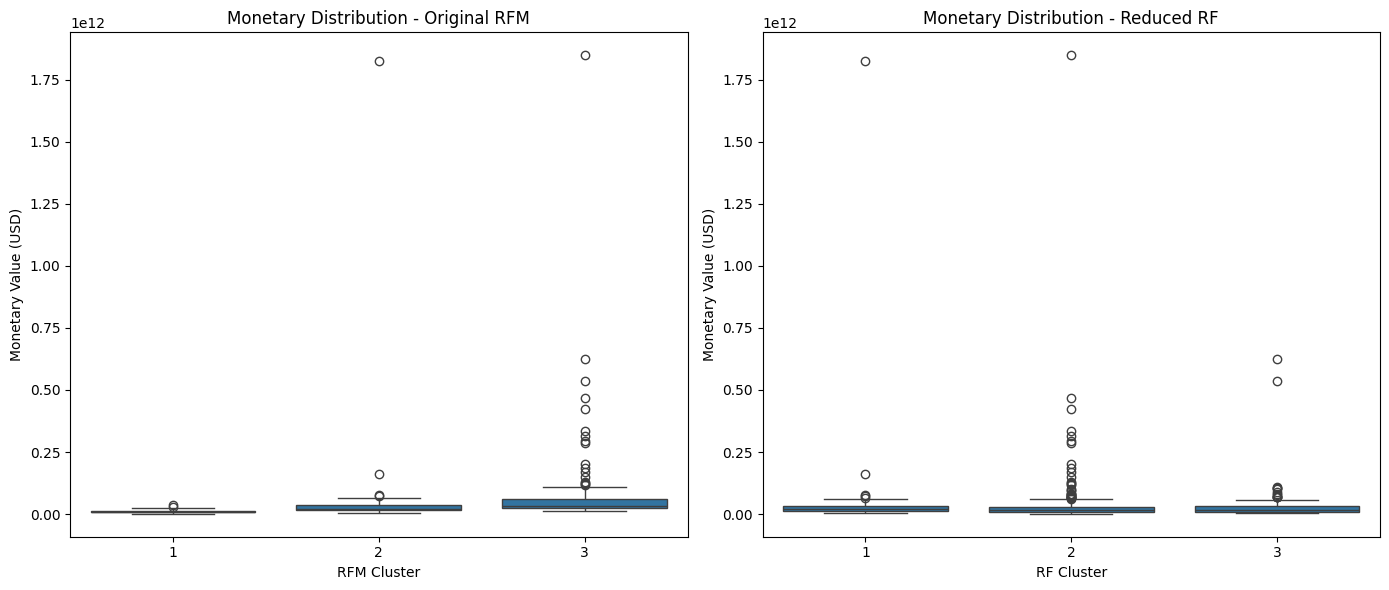

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original RFM
sns.boxplot(
    data=sensitivity_comparison,
    x='Original_RFM_Cluster',
    y='Monetary (USD)',
    ax=axes[0]
)

axes[0].set_title('Monetary Distribution - Original RFM')
axes[0].set_xlabel('RFM Cluster')
axes[0].set_ylabel('Monetary Value (USD)')

# Reduced RF
sns.boxplot(
    data=sensitivity_comparison,
    x='Reduced_RF_Cluster',
    y='Monetary (USD)',
    ax=axes[1]
)

axes[1].set_title('Monetary Distribution - Reduced RF')
axes[1].set_xlabel('RF Cluster')
axes[1].set_ylabel('Monetary Value (USD)')

plt.tight_layout()
plt.savefig('monetary_sensitivity_comparison.png', dpi=300)
plt.show()

#Task 3 Business Intelligence and Critical Review

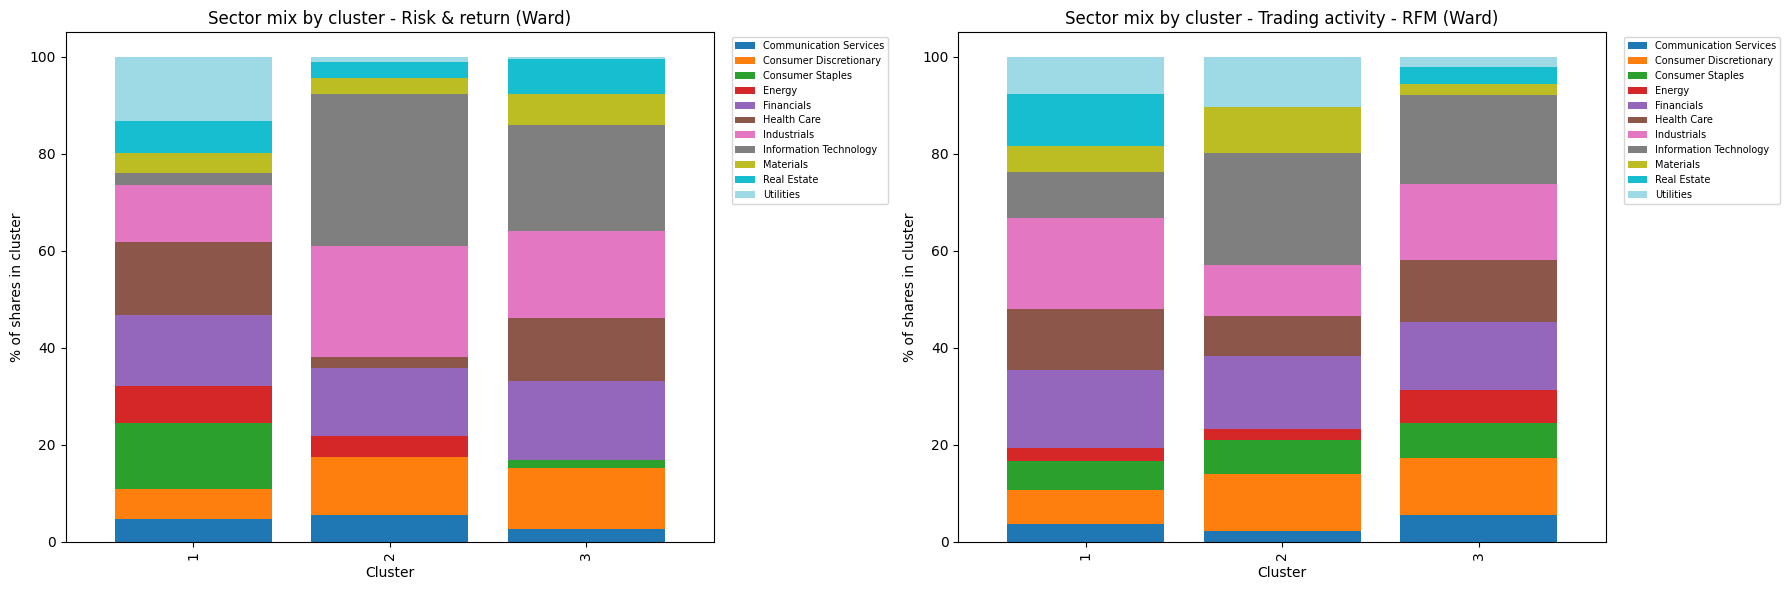

In [199]:
# ---------- CELL D: Task 3.2.1 - sector composition of every clustering ----------
sector = sp500_df.assign(Symbol=sp500_df['Symbol'].str.replace('.', '-', regex=False)) \
                 .set_index('Symbol')['GICS Sector']
fc = final_clusters.join(sector.rename('Sector'))

def sector_table(col):
    ct = pd.crosstab(fc[col], fc['Sector'])
    return ct, ct.div(ct.sum(axis=1), axis=0) * 100     # counts, % within cluster

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, col, title in [(axes[0], 'Risk_Agglomerative', 'Risk & return (Ward)'),
                       (axes[1], 'Activity_Agglomerative', 'Trading activity - RFM (Ward)')]:
    counts, pct = sector_table(col)
    pct.plot(kind='bar', stacked=True, ax=ax, colormap='tab20', width=0.8)
    ax.set_title(f'Sector mix by cluster - {title}')
    ax.set_xlabel('Cluster'); ax.set_ylabel('% of shares in cluster')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7)
plt.tight_layout(); plt.savefig('sector_composition.png', dpi=300); plt.show()

RFM cluster,1,2,3
Risk/return cluster,,,
1,103,33,76
2,30,20,42
3,90,33,61


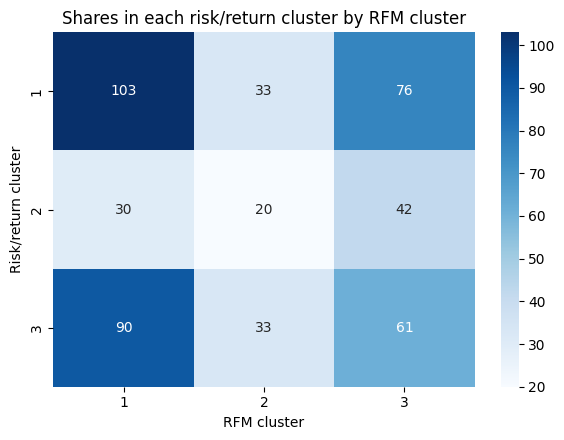

ARI risk vs RFM (Ward): 0.01


In [200]:
# ---------- CELL E: risk-return clusters vs RFM clusters (cross-tab + ARI) ----------
ct = pd.crosstab(fc['Risk_Agglomerative'], fc['Activity_Agglomerative'],
                 rownames=['Risk/return cluster'], colnames=['RFM cluster'])
display(ct)
plt.figure(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Shares in each risk/return cluster by RFM cluster')
plt.tight_layout(); plt.savefig('risk_vs_rfm_crosstab.png', dpi=300); plt.show()
print('ARI risk vs RFM (Ward):',
      round(adjusted_rand_score(fc['Risk_Agglomerative'], fc['Activity_Agglomerative']), 3))

In [201]:
# ---------- CELL F: name the specific shares in each RFM cluster (for "which stocks trade heavily") ----------
prof = activity_features.join(fc[['Activity_Agglomerative', 'Sector']])
for c, g in prof.groupby('Activity_Agglomerative'):
    top = g.sort_values('Monetary (USD)', ascending=False).head(10)
    print(f'\nRFM cluster {c}: {len(g)} shares | median R={g["Recency (Days)"].median():.0f} d, '
          f'median F={g["Frequency"].median():.0f}, median M=${g["Monetary (USD)"].median()/1e9:.1f}bn')
    print('Top 10 by traded value:', ', '.join(top.index))
    print('Top sectors:', g['Sector'].value_counts().head(3).to_dict())


RFM cluster 1: 223 shares | median R=11 d, median F=3, median M=$10.1bn
Top 10 by traded value: CI, AJG, CNC, HSY, LEN, WDC, TDG, DLR, DECK, MRNA
Top sectors: {'Industrials': 42, 'Financials': 36, 'Health Care': 28}

RFM cluster 2: 86 shares | median R=54 d, median F=2, median M=$21.5bn
Top 10 by traded value: NVDA, NFLX, NOW, CRWD, TXN, INTU, TMO, DELL, TGT, VST
Top sectors: {'Information Technology': 20, 'Financials': 13, 'Consumer Discretionary': 10}

RFM cluster 3: 179 shares | median R=11 d, median F=3, median M=$34.3bn
Top 10 by traded value: TSLA, AAPL, MSFT, AMZN, META, AVGO, AMD, GOOGL, PLTR, GOOG
Top sectors: {'Information Technology': 33, 'Industrials': 28, 'Financials': 25}


In [202]:
# ---------- CELL G: same thing for risk/return clusters ----------
prof2 = risk_features.join(fc[['Risk_Agglomerative', 'Sector']])
for c, g in prof2.groupby('Risk_Agglomerative'):
    print(f'\nRisk cluster {c}: {len(g)} shares | mean weekly return {g["Mean_Weekly_Return"].mean():.4f}, '
          f'mean beta {g["Beta"].mean():.2f}')
    print('Examples:', ', '.join(g.sort_values('Beta').index[[0, 1, -2, -1]]))
    print('Top sectors:', g['Sector'].value_counts().head(3).to_dict())


Risk cluster 1: 212 shares | mean weekly return 0.0025, mean beta 0.64
Examples: GIS, SJM, MAR, GE
Top sectors: {'Health Care': 32, 'Financials': 31, 'Consumer Staples': 29}

Risk cluster 2: 92 shares | mean weekly return 0.0063, mean beta 1.30
Examples: LLY, TRGP, NVDA, CVNA
Top sectors: {'Information Technology': 29, 'Industrials': 21, 'Financials': 13}

Risk cluster 3: 184 shares | mean weekly return 0.0015, mean beta 1.20
Examples: ECHO, FDS, COHR, XYZ
Top sectors: {'Information Technology': 40, 'Industrials': 33, 'Financials': 30}
